In [ ]:
import numpy as np
import os

from sklearn.model_selection import GroupShuffleSplit

BASE_PATH = "/content/drive/MyDrive/AI_Research_Paper_1"

PROCESSED_PATH = os.path.join(
    BASE_PATH,
    "processed"
)

MODEL_DATA_PATH = os.path.join(
    PROCESSED_PATH,
    "model_datasets"
)

LEAKY_PATH = os.path.join(
    PROCESSED_PATH,
    "leaky_datasets"
)

RESULTS_PATH = os.path.join(
    BASE_PATH,
    "results"
)

SPLIT_PATH = os.path.join(
    PROCESSED_PATH,
    "splits"
)

os.makedirs(SPLIT_PATH, exist_ok=True)

keys = [
    "code_module",
    "code_presentation",
    "id_student"
]

RANDOM_STATE = 42

print("Notebook 05 environment ready.")

Notebook 05 environment ready.


In [ ]:
print("MODEL_DATA_PATH exists:", os.path.exists(MODEL_DATA_PATH))
print("LEAKY_PATH exists:", os.path.exists(LEAKY_PATH))

for p in [10, 20, 30, 40]:

    lf_file = os.path.join(
        MODEL_DATA_PATH,
        f"leakage_free_{p}.csv"
    )

    leaky_file = os.path.join(
        LEAKY_PATH,
        f"leaky_{p}.csv"
    )

    print(f"\n{p}%")
    print("Leakage-free file:", os.path.exists(lf_file))
    print("Leaky file:", os.path.exists(leaky_file))

MODEL_DATA_PATH exists: True
LEAKY_PATH exists: True

10%
Leakage-free file: True
Leaky file: True

20%
Leakage-free file: True
Leaky file: True

30%
Leakage-free file: True
Leaky file: True

40%
Leakage-free file: True
Leaky file: True


In [ ]:
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import GroupShuffleSplit

BASE_PATH = "/content/drive/MyDrive/AI_Research_Paper_1"

PROCESSED_PATH = os.path.join(
    BASE_PATH,
    "processed"
)

MODEL_DATA_PATH = os.path.join(
    PROCESSED_PATH,
    "model_datasets"
)

LEAKY_PATH = os.path.join(
    PROCESSED_PATH,
    "leaky_datasets"
)

RESULTS_PATH = os.path.join(
    BASE_PATH,
    "results"
)

SPLIT_PATH = os.path.join(
    PROCESSED_PATH,
    "splits"
)

os.makedirs(SPLIT_PATH, exist_ok=True)

keys = [
    "code_module",
    "code_presentation",
    "id_student"
]

RANDOM_STATE = 42

print("Notebook 05 setup complete.")

Notebook 05 setup complete.


In [ ]:
lf_sets = {}
leaky_sets = {}

lf_sets[10] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_10.csv")
)
leaky_sets[10] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_10.csv")
)

lf_sets[20] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_20.csv")
)
leaky_sets[20] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_20.csv")
)

lf_sets[30] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_30.csv")
)
leaky_sets[30] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_30.csv")
)

lf_sets[40] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_40.csv")
)
leaky_sets[40] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_40.csv")
)

print("10%:", len(lf_sets[10]), len(leaky_sets[10]))
print("20%:", len(lf_sets[20]), len(leaky_sets[20]))
print("30%:", len(lf_sets[30]), len(leaky_sets[30]))
print("40%:", len(lf_sets[40]), len(leaky_sets[40]))

10%: 27652 27652
20%: 26595 26595
30%: 25783 25783
40%: 25119 25119


In [ ]:
lf_sets = {}
leaky_sets = {}

lf_sets[10] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_10.csv")
)
leaky_sets[10] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_10.csv")
)

lf_sets[20] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_20.csv")
)
leaky_sets[20] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_20.csv")
)

lf_sets[30] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_30.csv")
)
leaky_sets[30] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_30.csv")
)

lf_sets[40] = pd.read_csv(
    os.path.join(MODEL_DATA_PATH, "leakage_free_40.csv")
)
leaky_sets[40] = pd.read_csv(
    os.path.join(LEAKY_PATH, "leaky_40.csv")
)

print("10%:", len(lf_sets[10]), len(leaky_sets[10]))
print("20%:", len(lf_sets[20]), len(leaky_sets[20]))
print("30%:", len(lf_sets[30]), len(leaky_sets[30]))
print("40%:", len(lf_sets[40]), len(leaky_sets[40]))

10%: 27652 27652
20%: 26595 26595
30%: 25783 25783
40%: 25119 25119


In [ ]:
master_students = pd.concat(
    [
        lf_sets[10][["id_student"]],
        lf_sets[20][["id_student"]],
        lf_sets[30][["id_student"]],
        lf_sets[40][["id_student"]]
    ],
    ignore_index=True
)

master_students = (
    master_students
    .drop_duplicates()
    .sort_values("id_student")
    .reset_index(drop=True)
)

print(
    "Total unique students in master split:",
    len(master_students)
)

Total unique students in master split: 24954


In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        master_students,
        groups=master_students["id_student"]
    )
)

master_students["split"] = "train"

master_students.loc[
    test_idx,
    "split"
] = "test"

print(master_students["split"].value_counts())

print(
    "\nTrain percent:",
    round(
        (master_students["split"] == "train").mean() * 100,
        2
    )
)

print(
    "Test percent:",
    round(
        (master_students["split"] == "test").mean() * 100,
        2
    )
)

split
train    19963
test      4991
Name: count, dtype: int64

Train percent: 80.0
Test percent: 20.0


In [ ]:
train_students = set(
    master_students.loc[
        master_students["split"] == "train",
        "id_student"
    ]
)

test_students = set(
    master_students.loc[
        master_students["split"] == "test",
        "id_student"
    ]
)

overlap = train_students.intersection(test_students)

print("Student overlap:", len(overlap))

Student overlap: 0


In [ ]:
master_students.to_csv(
    os.path.join(
        SPLIT_PATH,
        "master_student_split.csv"
    ),
    index=False
)

print("Master student split saved successfully.")

Master student split saved successfully.


In [ ]:
split_audit = []

for p in [10, 20, 30, 40]:

    temp = lf_sets[p].merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    print(f"\n=== {p}% CUTOFF ===")

    print(
        "Missing split assignments:",
        temp["split"].isna().sum()
    )

    print("\nRegistrations:")
    print(temp["split"].value_counts())

    print("\nUnique students:")
    print(
        temp.groupby("split")["id_student"]
        .nunique()
    )

    class_percent = (
        pd.crosstab(
            temp["split"],
            temp["final_result"],
            normalize="index"
        )
        .mul(100)
        .round(2)
    )

    print("\nOutcome distribution (%):")
    print(class_percent)

    for outcome in [
        "Distinction",
        "Pass",
        "Fail",
        "Withdrawn"
    ]:

        split_audit.append({
            "Cutoff": f"{p}%",
            "Outcome": outcome,
            "Train_Percent":
                class_percent.loc["train", outcome],
            "Test_Percent":
                class_percent.loc["test", outcome],
            "Absolute_Difference":
                round(
                    abs(
                        class_percent.loc["train", outcome]
                        -
                        class_percent.loc["test", outcome]
                    ),
                    2
                )
        })

split_balance = pd.DataFrame(split_audit)

print("\n=== TRAIN–TEST BALANCE SUMMARY ===")
print(split_balance.to_string(index=False))


=== 10% CUTOFF ===
Missing split assignments: 0

Registrations:
split
train    22138
test      5514
Name: count, dtype: int64

Unique students:
split
test      4991
train    19953
Name: id_student, dtype: int64

Outcome distribution (%):
final_result  Distinction   Fail   Pass  Withdrawn
split                                             
test                10.52  26.50  44.83      18.15
train               11.03  25.16  44.64      19.17

=== 20% CUTOFF ===
Missing split assignments: 0

Registrations:
split
train    21274
test      5321
Name: count, dtype: int64

Unique students:
split
test      4843
train    19335
Name: id_student, dtype: int64

Outcome distribution (%):
final_result  Distinction   Fail   Pass  Withdrawn
split                                             
test                10.90  27.46  46.46      15.19
train               11.49  26.19  46.46      15.86

=== 30% CUTOFF ===
Missing split assignments: 0

Registrations:
split
train    20619
test      5164
Name: count, 

In [ ]:
split_balance.to_csv(
    os.path.join(
        RESULTS_PATH,
        "train_test_class_balance.csv"
    ),
    index=False
)

print("Split balance audit saved.")

Split balance audit saved.


In [ ]:
print("=== LEAKAGE-FREE 10% COLUMNS ===")
for col in lf_sets[10].columns:
    print(col)

print("\n=== LEAKY 10% COLUMNS ===")
for col in leaky_sets[10].columns:
    print(col)

=== LEAKAGE-FREE 10% COLUMNS ===
code_module
code_presentation
id_student
cutoff_day
final_result
vle_clicks_10
vle_active_days_10
vle_unique_sites_10
precourse_clicks
precourse_active_days
precourse_unique_sites
content_clicks_10
forum_clicks_10
navigation_clicks_10
assessments_submitted_10
tma_submitted_10
cma_submitted_10
late_submissions_10
mean_submission_delay_10
scored_assessments_10
mean_score_due_10
has_score_due_10
gender
region
highest_education
imd_band
age_band
num_of_prev_attempts
studied_credits
disability
date_registration

=== LEAKY 10% COLUMNS ===
code_module
code_presentation
id_student
cutoff_day
final_result
precourse_clicks
precourse_active_days
precourse_unique_sites
gender
region
highest_education
imd_band
age_band
num_of_prev_attempts
studied_credits
disability
date_registration
vle_clicks_full
vle_active_days_full
vle_unique_sites_full
content_clicks_full
forum_clicks_full
navigation_clicks_full
assessments_submitted_full
tma_submitted_full
cma_submitted_full


In [ ]:
print("Leakage-free columns:", len(lf_sets[10].columns))
print("Leaky columns:", len(leaky_sets[10].columns))

common_cols = set(lf_sets[10].columns).intersection(
    leaky_sets[10].columns
)

only_lf = sorted(
    set(lf_sets[10].columns) -
    set(leaky_sets[10].columns)
)

only_leaky = sorted(
    set(leaky_sets[10].columns) -
    set(lf_sets[10].columns)
)

print("\nOnly leakage-free:")
print(only_lf)

print("\nOnly leaky:")
print(only_leaky)

Leakage-free columns: 31
Leaky columns: 31

Only leakage-free:
['assessments_submitted_10', 'cma_submitted_10', 'content_clicks_10', 'forum_clicks_10', 'has_score_due_10', 'late_submissions_10', 'mean_score_due_10', 'mean_submission_delay_10', 'navigation_clicks_10', 'scored_assessments_10', 'tma_submitted_10', 'vle_active_days_10', 'vle_clicks_10', 'vle_unique_sites_10']

Only leaky:
['assessments_submitted_full', 'cma_submitted_full', 'content_clicks_full', 'forum_clicks_full', 'has_score_full', 'late_submissions_full', 'mean_score_full', 'mean_submission_delay_full', 'navigation_clicks_full', 'scored_assessments_full', 'tma_submitted_full', 'vle_active_days_full', 'vle_clicks_full', 'vle_unique_sites_full']


In [ ]:
def canonicalize_dataset(df, p, condition):

    data = df.copy()

    if condition == "leakage_free":

        rename_map = {
            f"vle_clicks_{p}": "vle_clicks",
            f"vle_active_days_{p}": "vle_active_days",
            f"vle_unique_sites_{p}": "vle_unique_sites",
            f"content_clicks_{p}": "content_clicks",
            f"forum_clicks_{p}": "forum_clicks",
            f"navigation_clicks_{p}": "navigation_clicks",

            f"assessments_submitted_{p}": "assessments_submitted",
            f"tma_submitted_{p}": "tma_submitted",
            f"cma_submitted_{p}": "cma_submitted",
            f"late_submissions_{p}": "late_submissions",
            f"mean_submission_delay_{p}": "mean_submission_delay",
            f"scored_assessments_{p}": "scored_assessments",
            f"mean_score_due_{p}": "mean_score",
            f"has_score_due_{p}": "has_score"
        }

    elif condition == "leaky":

        rename_map = {
            "vle_clicks_full": "vle_clicks",
            "vle_active_days_full": "vle_active_days",
            "vle_unique_sites_full": "vle_unique_sites",
            "content_clicks_full": "content_clicks",
            "forum_clicks_full": "forum_clicks",
            "navigation_clicks_full": "navigation_clicks",

            "assessments_submitted_full": "assessments_submitted",
            "tma_submitted_full": "tma_submitted",
            "cma_submitted_full": "cma_submitted",
            "late_submissions_full": "late_submissions",
            "mean_submission_delay_full": "mean_submission_delay",
            "scored_assessments_full": "scored_assessments",
            "mean_score_full": "mean_score",
            "has_score_full": "has_score"
        }

    else:
        raise ValueError(
            "condition must be 'leakage_free' or 'leaky'"
        )

    return data.rename(columns=rename_map)

In [ ]:
lf_10_model = canonicalize_dataset(
    lf_sets[10],
    10,
    "leakage_free"
)

leaky_10_model = canonicalize_dataset(
    leaky_sets[10],
    10,
    "leaky"
)

print("LF columns:", len(lf_10_model.columns))
print("Leaky columns:", len(leaky_10_model.columns))

print(
    "Same column names:",
    set(lf_10_model.columns)
    ==
    set(leaky_10_model.columns)
)

print(
    "Only LF:",
    sorted(
        set(lf_10_model.columns)
        -
        set(leaky_10_model.columns)
    )
)

print(
    "Only leaky:",
    sorted(
        set(leaky_10_model.columns)
        -
        set(lf_10_model.columns)
    )
)

LF columns: 31
Leaky columns: 31
Same column names: True
Only LF: []
Only leaky: []


In [ ]:
canonical_lf = {}
canonical_leaky = {}

for p in [10, 20, 30, 40]:

    canonical_lf[p] = canonicalize_dataset(
        lf_sets[p],
        p,
        "leakage_free"
    )

    canonical_leaky[p] = canonicalize_dataset(
        leaky_sets[p],
        p,
        "leaky"
    )

    same_columns = (
        set(canonical_lf[p].columns)
        ==
        set(canonical_leaky[p].columns)
    )

    print(
        f"{p}%:",
        "LF =", len(canonical_lf[p].columns),
        "| Leaky =", len(canonical_leaky[p].columns),
        "| Same schema =", same_columns
    )

10%: LF = 31 | Leaky = 31 | Same schema = True
20%: LF = 31 | Leaky = 31 | Same schema = True
30%: LF = 31 | Leaky = 31 | Same schema = True
40%: LF = 31 | Leaky = 31 | Same schema = True


In [ ]:
excluded_primary = [
    "id_student",      # grouping/identifier only
    "cutoff_day",      # experimental bookkeeping
    "final_result",    # TARGET
    "gender",          # retained for fairness analysis
    "disability",      # retained for fairness analysis
    "region"           # retained for subgroup/sensitivity analysis
]

categorical_features = [
    "code_module",
    "code_presentation",
    "highest_education",
    "imd_band",
    "age_band"
]

numeric_features = [
    "num_of_prev_attempts",
    "studied_credits",
    "date_registration",

    "precourse_clicks",
    "precourse_active_days",
    "precourse_unique_sites",

    "vle_clicks",
    "vle_active_days",
    "vle_unique_sites",
    "content_clicks",
    "forum_clicks",
    "navigation_clicks",

    "assessments_submitted",
    "tma_submitted",
    "cma_submitted",
    "late_submissions",
    "mean_submission_delay",
    "scored_assessments",
    "mean_score",
    "has_score"
]

primary_features = (
    categorical_features +
    numeric_features
)

print("Categorical predictors:", len(categorical_features))
print("Numeric predictors:", len(numeric_features))
print("Total primary predictors:", len(primary_features))

Categorical predictors: 5
Numeric predictors: 20
Total primary predictors: 25


In [ ]:
for p in [10, 20, 30, 40]:

    for condition, datasets in [
        ("Leakage-free", canonical_lf),
        ("Leaky", canonical_leaky)
    ]:

        missing = [
            col for col in primary_features
            if col not in datasets[p].columns
        ]

        print(
            f"{p}% {condition} missing predictors:",
            missing
        )

10% Leakage-free missing predictors: []
10% Leaky missing predictors: []
20% Leakage-free missing predictors: []
20% Leaky missing predictors: []
30% Leakage-free missing predictors: []
30% Leaky missing predictors: []
40% Leakage-free missing predictors: []
40% Leaky missing predictors: []


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [ ]:
lf10 = canonical_lf[10].merge(
    master_students,
    on="id_student",
    how="left",
    validate="many_to_one"
)

leaky10 = canonical_leaky[10].merge(
    master_students,
    on="id_student",
    how="left",
    validate="many_to_one"
)

print("LF rows:", len(lf10))
print("Leaky rows:", len(leaky10))

print(
    "Missing split assignments LF:",
    lf10["split"].isna().sum()
)

print(
    "Missing split assignments Leaky:",
    leaky10["split"].isna().sum()
)

LF rows: 27652
Leaky rows: 27652
Missing split assignments LF: 0
Missing split assignments Leaky: 0


In [ ]:
X_train_lf = lf10.loc[
    lf10["split"] == "train",
    primary_features
].copy()

X_test_lf = lf10.loc[
    lf10["split"] == "test",
    primary_features
].copy()

y_train = lf10.loc[
    lf10["split"] == "train",
    "final_result"
].copy()

y_test = lf10.loc[
    lf10["split"] == "test",
    "final_result"
].copy()


X_train_leaky = leaky10.loc[
    leaky10["split"] == "train",
    primary_features
].copy()

X_test_leaky = leaky10.loc[
    leaky10["split"] == "test",
    primary_features
].copy()

y_train_leaky = leaky10.loc[
    leaky10["split"] == "train",
    "final_result"
].copy()

y_test_leaky = leaky10.loc[
    leaky10["split"] == "test",
    "final_result"
].copy()

print("LF train:", X_train_lf.shape)
print("LF test:", X_test_lf.shape)

print("Leaky train:", X_train_leaky.shape)
print("Leaky test:", X_test_leaky.shape)

print(
    "\nSame training targets:",
    y_train.reset_index(drop=True).equals(
        y_train_leaky.reset_index(drop=True)
    )
)

print(
    "Same testing targets:",
    y_test.reset_index(drop=True).equals(
        y_test_leaky.reset_index(drop=True)
    )
)

LF train: (22138, 25)
LF test: (5514, 25)
Leaky train: (22138, 25)
Leaky test: (5514, 25)

Same training targets: True
Same testing targets: True


In [ ]:
print(
    "Protected variables entering primary model:",
    [
        col for col in
        ["gender", "disability", "region"]
        if col in primary_features
    ]
)

print(
    "Identifier entering model:",
    "id_student" in primary_features
)

print(
    "Target entering model:",
    "final_result" in primary_features
)

Protected variables entering primary model: []
Identifier entering model: False
Target entering model: False


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Baseline modelling tools ready.")

Baseline modelling tools ready.


In [ ]:
lf_logistic = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            LogisticRegression(
                solver="lbfgs",
                C=1.0,
                max_iter=2000
            )
        )
    ]
)

leaky_logistic = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            LogisticRegression(
                solver="lbfgs",
                C=1.0,
                max_iter=2000
            )
        )
    ]
)

print("Two independent logistic-regression pipelines created.")

Two independent logistic-regression pipelines created.


In [ ]:
lf_logistic.fit(
    X_train_lf,
    y_train
)

print("10% leakage-free logistic model trained.")

10% leakage-free logistic model trained.


In [ ]:
pred_lf = lf_logistic.predict(
    X_test_lf
)

print("Leakage-free predictions created.")

Leakage-free predictions created.


In [ ]:
lf_accuracy = accuracy_score(
    y_test,
    pred_lf
)

lf_balanced_accuracy = balanced_accuracy_score(
    y_test,
    pred_lf
)

lf_macro_f1 = f1_score(
    y_test,
    pred_lf,
    average="macro"
)

print("=== 10% LEAKAGE-FREE LOGISTIC REGRESSION ===")
print(
    "Accuracy:",
    round(lf_accuracy, 4)
)
print(
    "Balanced accuracy:",
    round(lf_balanced_accuracy, 4)
)
print(
    "Macro F1:",
    round(lf_macro_f1, 4)
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        pred_lf,
        digits=4
    )
)

=== 10% LEAKAGE-FREE LOGISTIC REGRESSION ===
Accuracy: 0.5221
Balanced accuracy: 0.377
Macro F1: 0.3799

Classification report:
              precision    recall  f1-score   support

 Distinction     0.5810    0.1052    0.1781       580
        Fail     0.4971    0.3491    0.4101      1461
        Pass     0.5432    0.8519    0.6634      2472
   Withdrawn     0.3992    0.2018    0.2681      1001

    accuracy                         0.5221      5514
   macro avg     0.5051    0.3770    0.3799      5514
weighted avg     0.5088    0.5221    0.4735      5514



In [ ]:
leaky_logistic.fit(
    X_train_leaky,
    y_train_leaky
)

print("10% leaky logistic model trained.")

10% leaky logistic model trained.


In [ ]:
pred_leaky = leaky_logistic.predict(
    X_test_leaky
)

print("Leaky predictions created.")

Leaky predictions created.


In [ ]:
leaky_accuracy = accuracy_score(
    y_test_leaky,
    pred_leaky
)

leaky_balanced_accuracy = balanced_accuracy_score(
    y_test_leaky,
    pred_leaky
)

leaky_macro_f1 = f1_score(
    y_test_leaky,
    pred_leaky,
    average="macro"
)

print("=== 10% LEAKY LOGISTIC REGRESSION ===")
print(
    "Accuracy:",
    round(leaky_accuracy, 4)
)
print(
    "Balanced accuracy:",
    round(leaky_balanced_accuracy, 4)
)
print(
    "Macro F1:",
    round(leaky_macro_f1, 4)
)

print("\nClassification report:")
print(
    classification_report(
        y_test_leaky,
        pred_leaky,
        digits=4
    )
)

=== 10% LEAKY LOGISTIC REGRESSION ===
Accuracy: 0.6665
Balanced accuracy: 0.5802
Macro F1: 0.5957

Classification report:
              precision    recall  f1-score   support

 Distinction     0.6443    0.3966    0.4909       580
        Fail     0.5744    0.5072    0.5387      1461
        Pass     0.7526    0.8738    0.8087      2472
   Withdrawn     0.5456    0.5435    0.5445      1001

    accuracy                         0.6665      5514
   macro avg     0.6292    0.5802    0.5957      5514
weighted avg     0.6564    0.6665    0.6558      5514



In [ ]:
baseline_comparison_10 = pd.DataFrame({
    "Condition": [
        "Leakage-Free",
        "Leaky"
    ],
    "Accuracy": [
        lf_accuracy,
        leaky_accuracy
    ],
    "Balanced_Accuracy": [
        lf_balanced_accuracy,
        leaky_balanced_accuracy
    ],
    "Macro_F1": [
        lf_macro_f1,
        leaky_macro_f1
    ]
})

baseline_comparison_10[
    [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1"
    ]
] = baseline_comparison_10[
    [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1"
    ]
].round(4)

baseline_comparison_10

,Condition,Accuracy,Balanced_Accuracy,Macro_F1
0,Leakage-Free,0.5221,0.3770,0.3799
1,Leaky,0.6665,0.5802,0.5957


In [ ]:
print(
    "Accuracy change:",
    round(
        leaky_accuracy -
        lf_accuracy,
        4
    )
)

print(
    "Balanced accuracy change:",
    round(
        leaky_balanced_accuracy -
        lf_balanced_accuracy,
        4
    )
)

print(
    "Macro-F1 change:",
    round(
        leaky_macro_f1 -
        lf_macro_f1,
        4
    )
)

Accuracy change: 0.1444
Balanced accuracy change: 0.2032
Macro-F1 change: 0.2158


In [ ]:
class_order = [
    "Distinction",
    "Pass",
    "Fail",
    "Withdrawn"
]

cm_lf = confusion_matrix(
    y_test,
    pred_lf,
    labels=class_order
)

cm_leaky = confusion_matrix(
    y_test_leaky,
    pred_leaky,
    labels=class_order
)

print("Leakage-free confusion matrix:")
print(
    pd.DataFrame(
        cm_lf,
        index=class_order,
        columns=class_order
    )
)

print("\nLeaky confusion matrix:")
print(
    pd.DataFrame(
        cm_leaky,
        index=class_order,
        columns=class_order
    )
)

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction           61   494    19          6
Pass                  32  2106   211        123
Fail                   7   769   510        175
Withdrawn              5   508   286        202

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          230   336     4         10
Pass                 117  2160   143         52
Fail                   6   323   741        391
Withdrawn              4    51   402        544


In [ ]:
h3_10 = pd.DataFrame({
    "Condition": [
        "Leakage-Free",
        "Leaky"
    ],
    "Fail_to_Withdrawn": [
        cm_lf[2, 3],
        cm_leaky[2, 3]
    ],
    "Withdrawn_to_Fail": [
        cm_lf[3, 2],
        cm_leaky[3, 2]
    ]
})

h3_10["Total_Fail_Withdrawn_Confusion"] = (
    h3_10["Fail_to_Withdrawn"]
    +
    h3_10["Withdrawn_to_Fail"]
)

h3_10

,Condition,Fail_to_Withdrawn,Withdrawn_to_Fail,Total_Fail_Withdrawn_Confusion
0,Leakage-Free,175,286,461
1,Leaky,391,402,793


In [ ]:
fail_withdraw_rates_10 = pd.DataFrame({
    "Condition": [
        "Leakage-Free",
        "Leaky"
    ],

    "Fail_as_Withdrawn_Percent": [
        round(
            cm_lf[2, 3] /
            cm_lf[2, :].sum() * 100,
            2
        ),
        round(
            cm_leaky[2, 3] /
            cm_leaky[2, :].sum() * 100,
            2
        )
    ],

    "Withdrawn_as_Fail_Percent": [
        round(
            cm_lf[3, 2] /
            cm_lf[3, :].sum() * 100,
            2
        ),
        round(
            cm_leaky[3, 2] /
            cm_leaky[3, :].sum() * 100,
            2
        )
    ]
})

fail_withdraw_rates_10

,Condition,Fail_as_Withdrawn_Percent,Withdrawn_as_Fail_Percent
0,Leakage-Free,11.98,28.57
1,Leaky,26.76,40.16


In [ ]:
h3_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_h3_confusion_10.csv"
    ),
    index=False
)

fail_withdraw_rates_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_h3_confusion_rates_10.csv"
    ),
    index=False
)

baseline_comparison_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_baseline_comparison_10.csv"
    ),
    index=False
)

print("10% logistic baseline results saved.")

10% logistic baseline results saved.


In [ ]:
def run_logistic_experiment(p):

    # ---------------------------------
    # 1. Attach frozen student split
    # ---------------------------------
    lf = canonical_lf[p].merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = canonical_leaky[p].merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    # ---------------------------------
    # 2. Prepare identical train/test sets
    # ---------------------------------
    X_train_lf = lf.loc[
        lf["split"] == "train",
        primary_features
    ].copy()

    X_test_lf = lf.loc[
        lf["split"] == "test",
        primary_features
    ].copy()

    y_train_lf = lf.loc[
        lf["split"] == "train",
        "final_result"
    ].copy()

    y_test_lf = lf.loc[
        lf["split"] == "test",
        "final_result"
    ].copy()


    X_train_leaky = leaky.loc[
        leaky["split"] == "train",
        primary_features
    ].copy()

    X_test_leaky = leaky.loc[
        leaky["split"] == "test",
        primary_features
    ].copy()

    y_train_leaky = leaky.loc[
        leaky["split"] == "train",
        "final_result"
    ].copy()

    y_test_leaky = leaky.loc[
        leaky["split"] == "test",
        "final_result"
    ].copy()

    # ---------------------------------
    # 3. Independent pipelines
    # ---------------------------------
    model_lf = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            (
                "model",
                LogisticRegression(
                    solver="lbfgs",
                    C=1.0,
                    max_iter=2000
                )
            )
        ]
    )

    model_leaky = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            (
                "model",
                LogisticRegression(
                    solver="lbfgs",
                    C=1.0,
                    max_iter=2000
                )
            )
        ]
    )

    # ---------------------------------
    # 4. Train
    # ---------------------------------
    model_lf.fit(
        X_train_lf,
        y_train_lf
    )

    model_leaky.fit(
        X_train_leaky,
        y_train_leaky
    )

    # ---------------------------------
    # 5. Predict
    # ---------------------------------
    pred_lf = model_lf.predict(
        X_test_lf
    )

    pred_leaky = model_leaky.predict(
        X_test_leaky
    )

    # ---------------------------------
    # 6. Performance metrics
    # ---------------------------------
    results = pd.DataFrame({
        "Cutoff": [f"{p}%", f"{p}%"],
        "Condition": [
            "Leakage-Free",
            "Leaky"
        ],
        "Accuracy": [
            accuracy_score(
                y_test_lf,
                pred_lf
            ),
            accuracy_score(
                y_test_leaky,
                pred_leaky
            )
        ],
        "Balanced_Accuracy": [
            balanced_accuracy_score(
                y_test_lf,
                pred_lf
            ),
            balanced_accuracy_score(
                y_test_leaky,
                pred_leaky
            )
        ],
        "Macro_F1": [
            f1_score(
                y_test_lf,
                pred_lf,
                average="macro"
            ),
            f1_score(
                y_test_leaky,
                pred_leaky,
                average="macro"
            )
        ]
    })

    # ---------------------------------
    # 7. Confusion matrices
    # ---------------------------------
    cm_lf_local = confusion_matrix(
        y_test_lf,
        pred_lf,
        labels=class_order
    )

    cm_leaky_local = confusion_matrix(
        y_test_leaky,
        pred_leaky,
        labels=class_order
    )

    # ---------------------------------
    # 8. H3 Fail/Withdrawn confusion
    # ---------------------------------
    h3 = pd.DataFrame({
        "Cutoff": [f"{p}%", f"{p}%"],
        "Condition": [
            "Leakage-Free",
            "Leaky"
        ],

        "Fail_to_Withdrawn": [
            cm_lf_local[2, 3],
            cm_leaky_local[2, 3]
        ],

        "Withdrawn_to_Fail": [
            cm_lf_local[3, 2],
            cm_leaky_local[3, 2]
        ]
    })

    h3["Total_Fail_Withdrawn_Confusion"] = (
        h3["Fail_to_Withdrawn"]
        +
        h3["Withdrawn_to_Fail"]
    )

    # ---------------------------------
    # Display
    # ---------------------------------
    print(
        f"\n========== {p}% CUTOFF =========="
    )

    print("\nPerformance:")
    print(
        results.round(4).to_string(
            index=False
        )
    )

    print("\nLeakage-free confusion matrix:")
    print(
        pd.DataFrame(
            cm_lf_local,
            index=class_order,
            columns=class_order
        )
    )

    print("\nLeaky confusion matrix:")
    print(
        pd.DataFrame(
            cm_leaky_local,
            index=class_order,
            columns=class_order
        )
    )

    return (
        results,
        h3,
        model_lf,
        model_leaky
    )

In [ ]:
results_20, h3_20, lf_model_20, leaky_model_20 = (
    run_logistic_experiment(20)
)


========== 20% CUTOFF ==========

Performance:
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   20% Leakage-Free    0.5606             0.3932    0.3948
   20%        Leaky    0.6745             0.5651    0.5848

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction           85   470    22          3
Pass                  46  2139   237         50
Fail                   5   709   684         63
Withdrawn              3   416   314         75

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          231   336     3         10
Pass                 117  2162   150         43
Fail                   5   325   891        240
Withdrawn              4    51   448        305


In [ ]:
results_20.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_baseline_comparison_20.csv"
    ),
    index=False
)

h3_20.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_h3_confusion_20.csv"
    ),
    index=False
)

print("20% logistic results saved.")

20% logistic results saved.


In [ ]:
results_30, h3_30, lf_model_30, leaky_model_30 = (
    run_logistic_experiment(30)
)


========== 30% CUTOFF ==========

Performance:
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   30% Leakage-Free    0.6007             0.4231    0.4257
   30%        Leaky    0.6847             0.5446    0.5624

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          131   441     7          1
Pass                  86  2131   235         20
Fail                  15   616   805         26
Withdrawn             11   314   290         35

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          231   336     4          9
Pass                 117  2163   159         33
Fail                   5   326   997        134
Withdrawn              4    52   449        145


In [ ]:
results_30.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_baseline_comparison_30.csv"
    ),
    index=False
)

h3_30.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_h3_confusion_30.csv"
    ),
    index=False
)

print("30% logistic results saved.")

30% logistic results saved.


In [ ]:
results_40, h3_40, lf_model_40, leaky_model_40 = (
    run_logistic_experiment(40)
)


========== 40% CUTOFF ==========

Performance:
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   40% Leakage-Free    0.6321             0.4372    0.4401
   40%        Leaky    0.6991             0.5252    0.5350

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          151   416    11          2
Pass                  85  2146   227         14
Fail                  12   571   867         12
Withdrawn              7   231   262         14

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          230   338     5          7
Pass                 117  2167   162         26
Fail                   6   328  1068         60
Withdrawn              4    53   407         50


In [ ]:
results_40.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_baseline_comparison_40.csv"
    ),
    index=False
)

h3_40.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_h3_confusion_40.csv"
    ),
    index=False
)

print("40% logistic results saved.")

40% logistic results saved.


In [ ]:
results_10_master = baseline_comparison_10.copy()
results_10_master.insert(
    0,
    "Cutoff",
    "10%"
)

logistic_all = pd.concat(
    [
        results_10_master,
        results_20,
        results_30,
        results_40
    ],
    ignore_index=True
)

logistic_all[
    [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1"
    ]
] = logistic_all[
    [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1"
    ]
].astype(float)
print(logistic_all.round(4).to_string(index=False))

Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   10% Leakage-Free    0.5221             0.3770    0.3799
   10%        Leaky    0.6665             0.5802    0.5957
   20% Leakage-Free    0.5606             0.3932    0.3948
   20%        Leaky    0.6745             0.5651    0.5848
   30% Leakage-Free    0.6007             0.4231    0.4257
   30%        Leaky    0.6847             0.5446    0.5624
   40% Leakage-Free    0.6321             0.4372    0.4401
   40%        Leaky    0.6991             0.5252    0.5350


In [ ]:
h1_rows = []

for p in ["10%", "20%", "30%", "40%"]:

    temp = logistic_all[
        logistic_all["Cutoff"] == p
    ]

    lf = temp[
        temp["Condition"] == "Leakage-Free"
    ].iloc[0]

    leaky = temp[
        temp["Condition"] == "Leaky"
    ].iloc[0]

    h1_rows.append({
        "Cutoff": p,

        "LF_Accuracy":
            lf["Accuracy"],
        "Leaky_Accuracy":
            leaky["Accuracy"],
        "Accuracy_Inflation":
            leaky["Accuracy"] -
            lf["Accuracy"],

        "LF_Balanced_Accuracy":
            lf["Balanced_Accuracy"],
        "Leaky_Balanced_Accuracy":
            leaky["Balanced_Accuracy"],
        "Balanced_Accuracy_Inflation":
            leaky["Balanced_Accuracy"] -
            lf["Balanced_Accuracy"],

        "LF_Macro_F1":
            lf["Macro_F1"],
        "Leaky_Macro_F1":
            leaky["Macro_F1"],
        "Macro_F1_Inflation":
            leaky["Macro_F1"] -
            lf["Macro_F1"]
    })

h1_summary = pd.DataFrame(h1_rows)

print(
    h1_summary
    .round(4)
    .to_string(index=False)
)

Cutoff  LF_Accuracy  Leaky_Accuracy  Accuracy_Inflation  LF_Balanced_Accuracy  Leaky_Balanced_Accuracy  Balanced_Accuracy_Inflation  LF_Macro_F1  Leaky_Macro_F1  Macro_F1_Inflation
   10%       0.5221          0.6665              0.1444                0.3770                   0.5802                       0.2032       0.3799          0.5957              0.2158
   20%       0.5606          0.6745              0.1139                0.3932                   0.5651                       0.1718       0.3948          0.5848              0.1900
   30%       0.6007          0.6847              0.0840                0.4231                   0.5446                       0.1215       0.4257          0.5624              0.1368
   40%       0.6321          0.6991              0.0670                0.4372                   0.5252                       0.0881       0.4401          0.5350              0.0949


In [ ]:
logistic_all.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_all_cutoffs_performance.csv"
    ),
    index=False
)

h1_summary.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_h1_inflation_summary.csv"
    ),
    index=False
)

print("Master logistic H1 results saved.")

Master logistic H1 results saved.


In [ ]:
h3_10_master = h3_10.copy()
h3_10_master.insert(
    0,
    "Cutoff",
    "10%"
)

h3_all = pd.concat(
    [
        h3_10_master,
        h3_20,
        h3_30,
        h3_40
    ],
    ignore_index=True
)

print(
    h3_all.to_string(index=False)
)

h3_all.to_csv(
    os.path.join(
        RESULTS_PATH,
        "logistic_h3_all_cutoffs.csv"
    ),
    index=False
    )

print("Master H3 table saved.")

Cutoff    Condition  Fail_to_Withdrawn  Withdrawn_to_Fail  Total_Fail_Withdrawn_Confusion
   10% Leakage-Free                175                286                             461
   10%        Leaky                391                402                             793
   20% Leakage-Free                 63                314                             377
   20%        Leaky                240                448                             688
   30% Leakage-Free                 26                290                             316
   30%        Leaky                134                449                             583
   40% Leakage-Free                 12                262                             274
   40%        Leaky                 60                407                             467
Master H3 table saved.


In [ ]:
# ============================================================
# NORMALISED H3 RATES — LOGISTIC REGRESSION
# Robust version: works whether "Cutoff" already exists or not
# ============================================================

import pandas as pd

h3_tables = {
    10: h3_10,
    20: h3_20,
    30: h3_30,
    40: h3_40
}

logistic_h3_rate_parts = []

for p in [10, 20, 30, 40]:

    # --------------------------------------------------------
    # 1. Get the test cohort for this cutoff
    # --------------------------------------------------------
    temp = canonical_lf[p].copy()

    if "split" not in temp.columns:
        temp = temp.merge(
            master_students,
            on="id_student",
            how="left",
            validate="many_to_one"
        )

    test_data = temp.loc[
        temp["split"] == "test"
    ].copy()

    # --------------------------------------------------------
    # 2. Count true Fail and Withdrawn cases
    # --------------------------------------------------------
    class_counts = test_data["final_result"].value_counts()

    fail_total = int(
        class_counts.get("Fail", 0)
    )

    withdrawn_total = int(
        class_counts.get("Withdrawn", 0)
    )

    adverse_total = fail_total + withdrawn_total

    # --------------------------------------------------------
    # 3. Copy existing H3 results
    # --------------------------------------------------------
    df = h3_tables[p].copy()

    # IMPORTANT:
    # overwrite Cutoff if it already exists
    # rather than trying to insert a second Cutoff column
    df["Cutoff"] = f"{p}%"

    # --------------------------------------------------------
    # 4. Add denominators
    # --------------------------------------------------------
    df["Fail_Total"] = fail_total
    df["Withdrawn_Total"] = withdrawn_total

    # --------------------------------------------------------
    # 5. Calculate directional error rates
    # --------------------------------------------------------
    df["Fail_to_Withdrawn_Percent"] = (
        df["Fail_to_Withdrawn"]
        / fail_total
        * 100
    )

    df["Withdrawn_to_Fail_Percent"] = (
        df["Withdrawn_to_Fail"]
        / withdrawn_total
        * 100
    )

    # Overall Fail–Withdrawn confusion rate
    df["Fail_Withdrawn_Confusion_Rate_Percent"] = (
        df["Total_Fail_Withdrawn_Confusion"]
        / adverse_total
        * 100
    )

    logistic_h3_rate_parts.append(df)


# ============================================================
# 6. Combine all cutoffs
# ============================================================

logistic_h3_rates = pd.concat(
    logistic_h3_rate_parts,
    ignore_index=True
)


# ============================================================
# 7. Round percentages
# ============================================================

rate_columns = [
    "Fail_to_Withdrawn_Percent",
    "Withdrawn_to_Fail_Percent",
    "Fail_Withdrawn_Confusion_Rate_Percent"
]

logistic_h3_rates[rate_columns] = (
    logistic_h3_rates[rate_columns]
    .round(2)
)


# ============================================================
# 8. Arrange columns neatly
# ============================================================

final_columns = [
    "Cutoff",
    "Condition",
    "Fail_Total",
    "Withdrawn_Total",
    "Fail_to_Withdrawn",
    "Fail_to_Withdrawn_Percent",
    "Withdrawn_to_Fail",
    "Withdrawn_to_Fail_Percent",
    "Total_Fail_Withdrawn_Confusion",
    "Fail_Withdrawn_Confusion_Rate_Percent"
]

logistic_h3_rates = logistic_h3_rates[final_columns]


# ============================================================
# 9. Show final table
# ============================================================

print("=== LOGISTIC REGRESSION: NORMALISED H3 RESULTS ===")

print(
    logistic_h3_rates
    .to_string(index=False)
)

=== LOGISTIC REGRESSION: NORMALISED H3 RESULTS ===
Cutoff    Condition  Fail_Total  Withdrawn_Total  Fail_to_Withdrawn  Fail_to_Withdrawn_Percent  Withdrawn_to_Fail  Withdrawn_to_Fail_Percent  Total_Fail_Withdrawn_Confusion  Fail_Withdrawn_Confusion_Rate_Percent
   10% Leakage-Free        1461             1001                175                      11.98                286                      28.57                             461                                  18.72
   10%        Leaky        1461             1001                391                      26.76                402                      40.16                             793                                  32.21
   20% Leakage-Free        1461              808                 63                       4.31                314                      38.86                             377                                  16.62
   20%        Leaky        1461              808                240                      16.43       

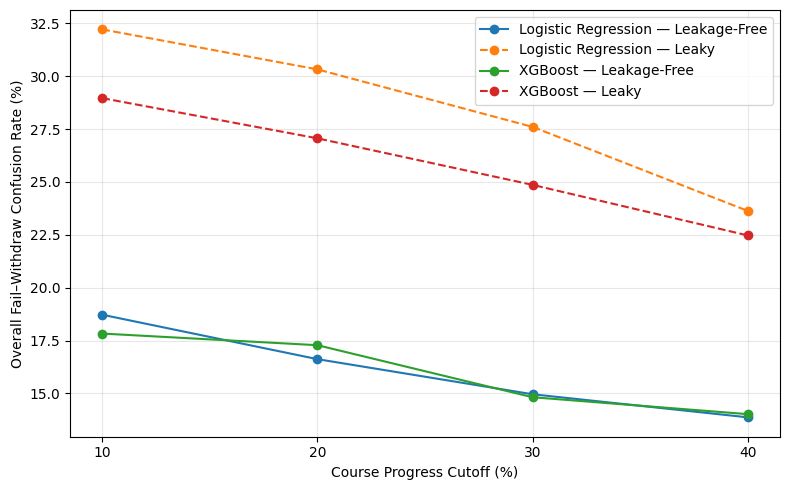

In [ ]:
import matplotlib.pyplot as plt

cutoffs = [10, 20, 30, 40]

# Overall Fail–Withdraw confusion rates (%)

logistic_lf = [18.72, 16.62, 14.96, 13.87]
logistic_leaky = [32.21, 30.32, 27.60, 23.63]

xgb_lf = [17.83, 17.28, 14.82, 14.02]
xgb_leaky = [28.96, 27.06, 24.86, 22.47]

plt.figure(figsize=(8, 5))

plt.plot(
    cutoffs,
    logistic_lf,
    marker="o",
    label="Logistic Regression — Leakage-Free"
)

plt.plot(
    cutoffs,
    logistic_leaky,
    marker="o",
    linestyle="--",
    label="Logistic Regression — Leaky"
)

plt.plot(
    cutoffs,
    xgb_lf,
    marker="o",
    label="XGBoost — Leakage-Free"
)

plt.plot(
    cutoffs,
    xgb_leaky,
    marker="o",
    linestyle="--",
    label="XGBoost — Leaky"
)

plt.xlabel("Course Progress Cutoff (%)")
plt.ylabel("Overall Fail–Withdraw Confusion Rate (%)")
plt.xticks(cutoffs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
print("=== LOGISTIC REGRESSION: H1 SUMMARY ===")

print(
    h1_summary[
        [
            "Cutoff",
            "LF_Accuracy",
            "Leaky_Accuracy",
            "Accuracy_Inflation",
            "LF_Macro_F1",
            "Leaky_Macro_F1",
            "Macro_F1_Inflation"
        ]
    ]
    .round(4)
    .to_string(index=False)
)

=== LOGISTIC REGRESSION: H1 SUMMARY ===
Cutoff  LF_Accuracy  Leaky_Accuracy  Accuracy_Inflation  LF_Macro_F1  Leaky_Macro_F1  Macro_F1_Inflation
   10%       0.5221          0.6665              0.1444       0.3799          0.5957              0.2158
   20%       0.5606          0.6745              0.1139       0.3948          0.5848              0.1900
   30%       0.6007          0.6847              0.0840       0.4257          0.5624              0.1368
   40%       0.6321          0.6991              0.0670       0.4401          0.5350              0.0949


In [ ]:
import xgboost as xgb

from xgboost import XGBClassifier

print("XGBoost version:", xgb.__version__)
print("XGBoost imported successfully.")

XGBoost version: 3.3.0
XGBoost imported successfully.


In [ ]:
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)
from sklearn.preprocessing import LabelEncoder

print("Grouped tuning tools ready.")

Grouped tuning tools ready.


In [ ]:
target_mapping = {
    "Distinction": 0,
    "Pass": 1,
    "Fail": 2,
    "Withdrawn": 3
}

inverse_target_mapping = {
    value: key
    for key, value in target_mapping.items()
}

print("Target mapping:")
print(target_mapping)

Target mapping:
{'Distinction': 0, 'Pass': 1, 'Fail': 2, 'Withdrawn': 3}


In [ ]:
y_train_xgb = (
    y_train
    .map(target_mapping)
    .astype(int)
)

y_test_xgb = (
    y_test
    .map(target_mapping)
    .astype(int)
)

y_train_leaky_xgb = (
    y_train_leaky
    .map(target_mapping)
    .astype(int)
)

y_test_leaky_xgb = (
    y_test_leaky
    .map(target_mapping)
    .astype(int)
)

print("LF training classes:")
print(y_train_xgb.value_counts().sort_index())

print("\nLF testing classes:")
print(y_test_xgb.value_counts().sort_index())
print(
    "\nSame encoded training targets:",
    y_train_xgb.reset_index(drop=True).equals(
        y_train_leaky_xgb.reset_index(drop=True)
    )
)

print(
    "Same encoded testing targets:",
    y_test_xgb.reset_index(drop=True).equals(
        y_test_leaky_xgb.reset_index(drop=True)
    )
)

LF training classes:
final_result
0    2442
1    9882
2    5570
3    4244
Name: count, dtype: int64

LF testing classes:
final_result
0     580
1    2472
2    1461
3    1001
Name: count, dtype: int64

Same encoded training targets: True
Same encoded testing targets: True


In [ ]:
groups_train_10 = (
    lf10.loc[
        lf10["split"] == "train",
        "id_student"
    ]
    .copy()
)

print("Training rows:", len(X_train_lf))
print("Group rows:", len(groups_train_10))
print(
    "Unique training students:",
    groups_train_10.nunique()
)

Training rows: 22138
Group rows: 22138
Unique training students: 19953


In [ ]:
group_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(
    group_cv.split(
        X_train_lf,
        y_train_xgb,
        groups=groups_train_10
    ),
    start=1
):

    fold_train_students = set(
        groups_train_10.iloc[train_idx]
    )

    fold_val_students = set(
        groups_train_10.iloc[val_idx]
    )

    overlap = (
        fold_train_students
        .intersection(fold_val_students)
    )

    print(f"\nFold {fold}")
    print("Train rows:", len(train_idx))
    print("Validation rows:", len(val_idx))
    print(
        "Student overlap:",
        len(overlap)
    )

    print("\nValidation class distribution (%):")
    print(
        y_train_xgb.iloc[val_idx]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )


Fold 1
Train rows: 14790
Validation rows: 7348
Student overlap: 0

Validation class distribution (%):
final_result
0    10.98
1    44.49
2    25.42
3    19.11
Name: proportion, dtype: float64

Fold 2
Train rows: 14752
Validation rows: 7386
Student overlap: 0

Validation class distribution (%):
final_result
0    10.99
1    44.77
2    25.41
3    18.82
Name: proportion, dtype: float64

Fold 3
Train rows: 14734
Validation rows: 7404
Student overlap: 0

Validation class distribution (%):
final_result
0    11.12
1    44.65
2    24.65
3    19.58
Name: proportion, dtype: float64


In [ ]:
tree_numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

tree_categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            tree_numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            tree_categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Tree preprocessing pipeline ready.")

Tree preprocessing pipeline ready.


In [ ]:
xgb_base = XGBClassifier(
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            tree_preprocessor
        ),
        (
            "model",
            xgb_base
        )
    ]
)

print("XGBoost pipeline ready.")

XGBoost pipeline ready.


In [ ]:
xgb_param_distributions = {

    "model__n_estimators": [
        200,
        300,
        400,
        500
    ],

    "model__max_depth": [
        3,
        4,
        5,
        6
    ],

    "model__learning_rate": [
        0.03,
        0.05,
        0.08,
        0.10
    ],

    "model__min_child_weight": [
        1,
        3,
        5,
        7
    ],

    "model__subsample": [
        0.70,
        0.80,
        0.90,
        1.00
    ],

    "model__colsample_bytree": [
        0.70,
        0.80,
        0.90,
        1.00
    ],

    "model__gamma": [
        0,
        0.1,
        0.3
    ],

    "model__reg_alpha": [
        0,
        0.01,
        0.1
    ],

    "model__reg_lambda": [
        1,
        2,
        5,
        10
    ]
}

print("XGBoost tuning space defined.")

XGBoost tuning space defined.


In [ ]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=15,
    scoring="f1_macro",
    cv=group_cv,
    random_state=42,
    verbose=2,
    n_jobs=1,
    refit=True,
    return_train_score=True
)

print("Starting grouped XGBoost tuning...")

xgb_search.fit(
    X_train_lf,
    y_train_xgb,
    groups=groups_train_10
)

print("\nTuning finished.")

Starting grouped XGBoost tuning...
Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END model__colsample_bytree=1.0, model__gamma=0, model__learning_rate=0.1, model__max_depth=5, model__min_child_weight=7, model__n_estimators=200, model__reg_alpha=0.1, model__reg_lambda=2, model__subsample=0.9; total time=   8.0s
[CV] END model__colsample_bytree=1.0, model__gamma=0, model__learning_rate=0.1, model__max_depth=5, model__min_child_weight=7, model__n_estimators=200, model__reg_alpha=0.1, model__reg_lambda=2, model__subsample=0.9; total time=  14.0s
[CV] END model__colsample_bytree=1.0, model__gamma=0, model__learning_rate=0.1, model__max_depth=5, model__min_child_weight=7, model__n_estimators=200, model__reg_alpha=0.1, model__reg_lambda=2, model__subsample=0.9; total time=   3.1s
[CV] END model__colsample_bytree=1.0, model__gamma=0.3, model__learning_rate=0.1, model__max_depth=6, model__min_child_weight=1, model__n_estimators=500, model__reg_alpha=0.1, model__reg_lambda=1,

In [ ]:
tuning_results = pd.DataFrame(
    xgb_search.cv_results_
)

tuning_results.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_grouped_tuning_10pct_LF.csv"
    ),
    index=False
)

print("XGBoost tuning results saved.")

XGBoost tuning results saved.


In [ ]:
best_idx = xgb_search.best_index_

best_cv_f1 = xgb_search.best_score_

best_train_f1 = (
    xgb_search.cv_results_[
        "mean_train_score"
    ][best_idx]
)

best_cv_std = (
    xgb_search.cv_results_[
        "std_test_score"
    ][best_idx]
)

print("=== BEST XGBOOST CONFIGURATION ===")

print(
    "Best CV Macro-F1:",
    round(best_cv_f1, 4)
)

print(
    "Mean training Macro-F1:",
    round(best_train_f1, 4)
)

print("Train-CV gap:",
    round(
        best_train_f1 - best_cv_f1,
        4
    )
)

print(
    "CV standard deviation:",
    round(best_cv_std, 4)
)

print("\nBest parameters:")

for parameter, value in (
    xgb_search.best_params_.items()
):
    print(
        parameter,
        "=",
        value
    )

=== BEST XGBOOST CONFIGURATION ===
Best CV Macro-F1: 0.4062
Mean training Macro-F1: 0.6079
Train-CV gap: 0.2017
CV standard deviation: 0.0059

Best parameters:
model__subsample = 0.7
model__reg_lambda = 10
model__reg_alpha = 0.01
model__n_estimators = 200
model__min_child_weight = 7
model__max_depth = 6
model__learning_rate = 0.08
model__gamma = 0.1
model__colsample_bytree = 1.0


In [ ]:
best_params_table = pd.DataFrame({
    "Parameter":
        list(
            xgb_search.best_params_.keys()
        ),

    "Value": [
        str(value)
        for value in
        xgb_search.best_params_.values()
    ]
})

best_params_table.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_best_parameters.csv"
    ),
    index=False
)

print(
    "Best XGBoost parameters saved."
)

Best XGBoost parameters saved.


In [ ]:
candidate_audit = pd.DataFrame(
    xgb_search.cv_results_
).copy()

candidate_audit["Train_CV_Gap"] = (
    candidate_audit["mean_train_score"]
    -
    candidate_audit["mean_test_score"]
)

candidate_audit = candidate_audit[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "Train_CV_Gap",
        "params"
    ]
].sort_values(
    ["rank_test_score", "Train_CV_Gap"]
)

pd.set_option("display.max_colwidth", None)

print(
    candidate_audit.head(15).to_string(
        index=False
    )
)

 rank_test_score  mean_test_score  std_test_score  mean_train_score  Train_CV_Gap                                                                                                                                                                                                                                           params
               1         0.406166        0.005930          0.607863      0.201697 {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0.01, 'model__n_estimators': 200, 'model__min_child_weight': 7, 'model__max_depth': 6, 'model__learning_rate': 0.08, 'model__gamma': 0.1, 'model__colsample_bytree': 1.0}
               2         0.405705        0.003400          0.738411      0.332707     {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__gamma': 0.3, 'model__colsample_bytree': 0.9}
               3         0.4029

In [ ]:
best_score = xgb_search.best_score_

near_best = candidate_audit[
    candidate_audit["mean_test_score"]
    >= best_score - 0.01
].copy()

near_best = near_best.sort_values(
    [
        "Train_CV_Gap",
        "mean_test_score"
    ],
    ascending=[
        True,
        False
    ]
)

print(
    near_best.to_string(
        index=False
    )
)

 rank_test_score  mean_test_score  std_test_score  mean_train_score  Train_CV_Gap                                                                                                                                                                                                                                           params
               5         0.399720        0.005724          0.466072      0.066352   {'model__subsample': 0.7, 'model__reg_lambda': 2, 'model__reg_alpha': 0.1, 'model__n_estimators': 500, 'model__min_child_weight': 3, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__gamma': 0.1, 'model__colsample_bytree': 1.0}
               9         0.396285        0.005078          0.465422      0.069138     {'model__subsample': 1.0, 'model__reg_lambda': 2, 'model__reg_alpha': 0.01, 'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__gamma': 0, 'model__colsample_bytree': 1.0}
               8         0.3972

In [ ]:
print("Number of near-best candidates:", len(near_best))

print(
    "\nLowest train-CV gap among near-best candidates:",
    round(
        near_best["Train_CV_Gap"].min(),
        4
    )
)

print(
    "\nHighest CV Macro-F1 among near-best candidates:",
    round(
        near_best["mean_test_score"].max(),
        4
    )
)

Number of near-best candidates: 9

Lowest train-CV gap among near-best candidates: 0.0664

Highest CV Macro-F1 among near-best candidates: 0.4062


In [ ]:
selected_candidate = near_best.iloc[0]

print("=== SELECTED XGBOOST MODEL ===")

print(
    "CV Macro-F1:",
    round(selected_candidate["mean_test_score"], 4)
)

print(
    "Training Macro-F1:",
    round(selected_candidate["mean_train_score"], 4)
)

print(
    "Train-CV gap:",
    round(selected_candidate["Train_CV_Gap"], 4)
)

print(
    "CV standard deviation:",
    round(selected_candidate["std_test_score"], 4)
)

print("\nSelected parameters:")

for parameter, value in selected_candidate["params"].items():
    print(parameter, "=", value)

=== SELECTED XGBOOST MODEL ===
CV Macro-F1: 0.3997
Training Macro-F1: 0.4661
Train-CV gap: 0.0664
CV standard deviation: 0.0057

Selected parameters:
model__subsample = 0.7
model__reg_lambda = 2
model__reg_alpha = 0.1
model__n_estimators = 500
model__min_child_weight = 3
model__max_depth = 3
model__learning_rate = 0.05
model__gamma = 0.1
model__colsample_bytree = 1.0


In [ ]:
selected_xgb_params = selected_candidate["params"].copy()

print("Selected XGBoost parameters frozen.")

Selected XGBoost parameters frozen.


In [ ]:
selected_params_table = pd.DataFrame({
    "Parameter": list(selected_xgb_params.keys()),
    "Value": [
        str(v)
        for v in selected_xgb_params.values()
    ]
})

selected_params_table.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_selected_conservative_parameters.csv"
    ),
    index=False
)

print("Selected XGBoost parameters saved.")

Selected XGBoost parameters saved.


In [ ]:
selection_audit = pd.DataFrame({
    "Model": [
        "Highest-CV candidate",
        "Selected near-best candidate"
    ],
    "CV_Macro_F1": [
        best_cv_f1,
        selected_candidate["mean_test_score"]
    ],
    "Train_Macro_F1": [
        best_train_f1,
        selected_candidate["mean_train_score"]
    ],
    "Train_CV_Gap": [
        best_train_f1 - best_cv_f1,
        selected_candidate["Train_CV_Gap"]
    ],
    "CV_SD": [
        best_cv_std,
        selected_candidate["std_test_score"]
    ]
})

print(
    selection_audit
    .round(4)
    .to_string(index=False)
)

selection_audit.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_model_selection_audit.csv"
    ),
    index=False
)

                       Model  CV_Macro_F1  Train_Macro_F1  Train_CV_Gap  CV_SD
        Highest-CV candidate       0.4062          0.6079        0.2017 0.0059
Selected near-best candidate       0.3997          0.4661        0.0664 0.0057


In [ ]:
print("=== FINAL SELECTED XGBOOST PARAMETERS ===")

for parameter, value in selected_xgb_params.items():
    print(parameter, "=", value)

=== FINAL SELECTED XGBOOST PARAMETERS ===
model__subsample = 0.7
model__reg_lambda = 2
model__reg_alpha = 0.1
model__n_estimators = 500
model__min_child_weight = 3
model__max_depth = 3
model__learning_rate = 0.05
model__gamma = 0.1
model__colsample_bytree = 1.0


In [ ]:
print("\nSelected CV Macro-F1:",
      round(selected_candidate["mean_test_score"], 4))

print("Selected Train Macro-F1:",
      round(selected_candidate["mean_train_score"], 4))

print("Selected Train-CV gap:",
      round(selected_candidate["Train_CV_Gap"], 4))

print("Selected CV SD:",
      round(selected_candidate["std_test_score"], 4))


Selected CV Macro-F1: 0.3997
Selected Train Macro-F1: 0.4661
Selected Train-CV gap: 0.0664
Selected CV SD: 0.0057


In [ ]:
print("=== FINAL SELECTED XGBOOST PARAMETERS ===")

for parameter, value in selected_xgb_params.items():
    print(parameter, "=", value)

=== FINAL SELECTED XGBOOST PARAMETERS ===
model__subsample = 0.7
model__reg_lambda = 2
model__reg_alpha = 0.1
model__n_estimators = 500
model__min_child_weight = 3
model__max_depth = 3
model__learning_rate = 0.05
model__gamma = 0.1
model__colsample_bytree = 1.0


In [ ]:
frozen_xgb_params = {
    key.replace("model__", ""): value
    for key, value in selected_xgb_params.items()
}

print("=== FROZEN XGBOOST PARAMETERS ===")

for key, value in frozen_xgb_params.items():
    print(key, "=", value)

=== FROZEN XGBOOST PARAMETERS ===
subsample = 0.7
reg_lambda = 2
reg_alpha = 0.1
n_estimators = 500
min_child_weight = 3
max_depth = 3
learning_rate = 0.05
gamma = 0.1
colsample_bytree = 1.0


In [ ]:
def run_xgb_experiment(p):

    # ==========================================
    # 1. Attach permanent student split
    # ==========================================
    lf = canonical_lf[p].merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = canonical_leaky[p].merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    # Keep identical registration ordering
    lf = (
        lf.sort_values(keys)
        .reset_index(drop=True)
    )

    leaky = (
        leaky.sort_values(keys)
        .reset_index(drop=True)
    )

    # ==========================================
    # 2. Train/test data
    # ==========================================
    X_train_lf = lf.loc[
        lf["split"] == "train",
        primary_features
    ].copy()

    X_test_lf = lf.loc[
        lf["split"] == "test",
        primary_features
    ].copy()

    y_train_lf = (
        lf.loc[
            lf["split"] == "train",
            "final_result"
        ]
        .map(target_mapping)
        .astype(int)
    )

    y_test_lf = (
        lf.loc[
            lf["split"] == "test",
            "final_result"
        ]
        .map(target_mapping)
        .astype(int)
    )


    X_train_leaky = leaky.loc[
        leaky["split"] == "train",
        primary_features
    ].copy()

    X_test_leaky = leaky.loc[
        leaky["split"] == "test",
        primary_features
    ].copy()

    y_train_leaky = (
        leaky.loc[
            leaky["split"] == "train",
            "final_result"
        ]
        .map(target_mapping)
        .astype(int)
    )

    y_test_leaky = (
        leaky.loc[
            leaky["split"] == "test",
            "final_result"
        ]
        .map(target_mapping)
        .astype(int)
    )

    # Important paired-data checks
    assert len(X_train_lf) == len(X_train_leaky)
    assert len(X_test_lf) == len(X_test_leaky)

    assert (
        y_train_lf.reset_index(drop=True)
        .equals(
            y_train_leaky.reset_index(drop=True)
        )
    )

    assert (
        y_test_lf.reset_index(drop=True)
        .equals(
            y_test_leaky.reset_index(drop=True)
        )
    )

    # ==========================================
    # 3. Build completely independent pipelines
    # ==========================================
    model_lf = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(tree_preprocessor)
            ),
            (
                "model",
                XGBClassifier(
                    **frozen_xgb_params,
                    objective="multi:softprob",
                    num_class=4,
                    eval_metric="mlogloss",
                    tree_method="hist",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    model_leaky = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(tree_preprocessor)
            ),
            (
                "model",
                XGBClassifier(
                    **frozen_xgb_params,
                    objective="multi:softprob",
                    num_class=4,
                    eval_metric="mlogloss",
                    tree_method="hist",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    # ==========================================
    # 4. Train
    # ==========================================
    print(f"\nTraining {p}% leakage-free model...")
    model_lf.fit(
        X_train_lf,
        y_train_lf
    )

    print(f"Training {p}% leaky model...")
    model_leaky.fit(
        X_train_leaky,
        y_train_leaky
    )

    # ==========================================
    # 5. Predict
    # ==========================================
    pred_lf = model_lf.predict(
        X_test_lf
    )

    pred_leaky = model_leaky.predict(
        X_test_leaky
    )

    # ==========================================
    # 6. Main performance
    # ==========================================
    results = pd.DataFrame({
        "Cutoff": [
            f"{p}%",
            f"{p}%"
        ],

        "Condition": [
            "Leakage-Free",
            "Leaky"
        ],

        "Accuracy": [
            accuracy_score(
                y_test_lf,
                pred_lf
            ),
            accuracy_score(
                y_test_leaky,
                pred_leaky
            )
        ],

        "Balanced_Accuracy": [
            balanced_accuracy_score(
                y_test_lf,
                pred_lf
            ),
            balanced_accuracy_score(
                y_test_leaky,
                pred_leaky
            )
        ],

        "Macro_F1": [
            f1_score(
                y_test_lf,
                pred_lf,
                average="macro"
            ),
            f1_score(
                y_test_leaky,
                pred_leaky,
                average="macro"
            )
        ]
    })

    # ==========================================
    # 7. Confusion matrices
    # ==========================================
    labels_numeric = [0, 1, 2, 3]

    cm_lf = confusion_matrix(
        y_test_lf,
        pred_lf,
        labels=labels_numeric
    )

    cm_leaky = confusion_matrix(
        y_test_leaky,
        pred_leaky,
        labels=labels_numeric
    )

    # ==========================================
    # 8. Fail <-> Withdrawn audit
    # ==========================================
    h3 = pd.DataFrame({
        "Cutoff": [
            f"{p}%",
            f"{p}%"
        ],

        "Condition": [
            "Leakage-Free",
            "Leaky"
        ],

        "Fail_to_Withdrawn": [
            cm_lf[2, 3],
            cm_leaky[2, 3]
        ],

        "Withdrawn_to_Fail": [
            cm_lf[3, 2],
            cm_leaky[3, 2]
        ],

        "Fail_to_Withdrawn_Percent": [
            cm_lf[2, 3] /
            cm_lf[2, :].sum() * 100,

            cm_leaky[2, 3] /
            cm_leaky[2, :].sum() * 100
        ],

        "Withdrawn_to_Fail_Percent": [
            cm_lf[3, 2] /
            cm_lf[3, :].sum() * 100,

            cm_leaky[3, 2] /
            cm_leaky[3, :].sum() * 100
        ]
    })

    h3["Total_Fail_Withdrawn_Confusion"] = (
        h3["Fail_to_Withdrawn"]
        +
        h3["Withdrawn_to_Fail"]
    )

    # ==========================================
    # 9. Print results
    # ==========================================
    print(
        f"\n========== XGBOOST {p}% =========="
    )

    print("\nPerformance:")
    print(
        results
        .round(4)
        .to_string(index=False)
    )

    print("\nLeakage-free confusion matrix:")

    print(
        pd.DataFrame(
            cm_lf,
            index=class_order,
            columns=class_order
        )
    )

    print("\nLeaky confusion matrix:")

    print(
        pd.DataFrame(
            cm_leaky,
            index=class_order,
            columns=class_order
        )
    )

    print("\nFail/Withdrawn audit:")

    print(
        h3
        .round(2)
        .to_string(index=False)
    )

    return (
        results,
        h3,
        model_lf,
        model_leaky
    )

In [ ]:
xgb_results_10, xgb_h3_10, xgb_lf_10, xgb_leaky_10 = (
    run_xgb_experiment(10)
)


Training 10% leakage-free model...
Training 10% leaky model...

========== XGBOOST 10% ==========

Performance:
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   10% Leakage-Free    0.5359             0.3990    0.4088
   10%        Leaky    0.7055             0.6264    0.6425

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction           86   475    16          3
Pass                  54  2091   221        106
Fail                  11   736   558        156
Withdrawn             11   487   283        220

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          270   307     2          1
Pass                 126  2231    82         33
Fail                   2   313   795        351
Withdrawn              4    41   362        594

Fail/Withdrawn audit:
Cutoff    Condition  Fail_to_Withdrawn  Withdrawn_to_Fail  Fail_to_Withdrawn_Percent  Withdrawn_to_Fail_Percent  Total_Fail_Withdrawn_Confusion
   10%

In [ ]:
xgb_results_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_comparison_10.csv"
    ),
    index=False
)

xgb_h3_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_h3_10.csv"
    ),
    index=False
)

print("10% XGBoost results saved.")

10% XGBoost results saved.


In [ ]:
xgb_results_20, xgb_h3_20, xgb_lf_20, xgb_leaky_20 = (
    run_xgb_experiment(20)
)


Training 20% leakage-free model...
Training 20% leaky model...

========== XGBOOST 20% ==========

Performance:
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   20% Leakage-Free    0.5781             0.4334     0.448
   20%        Leaky    0.7142             0.6209     0.641

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          146   421    10          3
Pass                  83  2097   243         49
Fail                   9   644   718         90
Withdrawn              7   384   302        115

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          269   308     2          1
Pass                 118  2233    85         36
Fail                   2   310   886        263
Withdrawn              4    41   351        412

Fail/Withdrawn audit:
Cutoff    Condition  Fail_to_Withdrawn  Withdrawn_to_Fail  Fail_to_Withdrawn_Percent  Withdrawn_to_Fail_Percent  Total_Fail_Withdrawn_Confusion
   20%

In [ ]:
xgb_results_20.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_comparison_20.csv"
    ),
    index=False
)

xgb_h3_20.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_h3_20.csv"
    ),
    index=False
)

print("20% XGBoost results saved.")

20% XGBoost results saved.


In [ ]:
xgb_results_30, xgb_h3_30, xgb_lf_30, xgb_leaky_30 = (
    run_xgb_experiment(30)
)


Training 30% leakage-free model...
Training 30% leaky model...

========== XGBOOST 30% ==========

Performance:
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   30% Leakage-Free    0.6172             0.4524    0.4624
   30%        Leaky    0.7217             0.6069    0.6303

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          176   398     5          1
Pass                 104  2136   209         23
Fail                  11   594   824         33
Withdrawn             11   308   280         51

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          271   306     2          1
Pass                 119  2230    89         34
Fail                   2   312   969        179
Withdrawn              4    43   346        257

Fail/Withdrawn audit:
Cutoff    Condition  Fail_to_Withdrawn  Withdrawn_to_Fail  Fail_to_Withdrawn_Percent  Withdrawn_to_Fail_Percent  Total_Fail_Withdrawn_Confusion
   30%

In [ ]:
xgb_results_30.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_comparison_30.csv"
    ),
    index=False
)

xgb_h3_30.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_h3_30.csv"
    ),
    index=False
)

print("30% XGBoost results saved.")

30% XGBoost results saved.


In [ ]:
xgb_results_40, xgb_h3_40, xgb_lf_40, xgb_leaky_40 = (
    run_xgb_experiment(40)
)


Training 40% leakage-free model...
Training 40% leaky model...

========== XGBOOST 40% ==========

Performance:
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   40% Leakage-Free    0.6504             0.4690    0.4770
   40%        Leaky    0.7301             0.5856    0.6102

Leakage-free confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          197   375     7          1
Pass                 109  2136   214         13
Fail                  13   518   912         19
Withdrawn              6   225   258         25

Leaky confusion matrix:
             Distinction  Pass  Fail  Withdrawn
Distinction          265   312     2          1
Pass                 114  2235    91         32
Fail                   4   311  1028        119
Withdrawn              4    42   325        143

Fail/Withdrawn audit:
Cutoff    Condition  Fail_to_Withdrawn  Withdrawn_to_Fail  Fail_to_Withdrawn_Percent  Withdrawn_to_Fail_Percent  Total_Fail_Withdrawn_Confusion
   40%

In [ ]:
xgb_results_40.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_comparison_40.csv"
    ),
    index=False
)

xgb_h3_40.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_h3_40.csv"
    ),
    index=False
)

print("40% XGBoost results saved.")

40% XGBoost results saved.


In [ ]:
xgb_all = pd.concat(
    [
        xgb_results_10,
        xgb_results_20,
        xgb_results_30,
        xgb_results_40
    ],
    ignore_index=True
)

print("=== XGBOOST ALL-CUTOFF PERFORMANCE ===")

print(
    xgb_all
    .round(4)
    .to_string(index=False)
)

=== XGBOOST ALL-CUTOFF PERFORMANCE ===
Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   10% Leakage-Free    0.5359             0.3990    0.4088
   10%        Leaky    0.7055             0.6264    0.6425
   20% Leakage-Free    0.5781             0.4334    0.4480
   20%        Leaky    0.7142             0.6209    0.6410
   30% Leakage-Free    0.6172             0.4524    0.4624
   30%        Leaky    0.7217             0.6069    0.6303
   40% Leakage-Free    0.6504             0.4690    0.4770
   40%        Leaky    0.7301             0.5856    0.6102


In [ ]:
xgb_h1_rows = []

for p in ["10%", "20%", "30%", "40%"]:

    temp = xgb_all[
        xgb_all["Cutoff"] == p
    ]

    lf = temp[
        temp["Condition"] == "Leakage-Free"
    ].iloc[0]

    leaky = temp[
        temp["Condition"] == "Leaky"
    ].iloc[0]

    xgb_h1_rows.append({

        "Cutoff": p,

        "LF_Accuracy":
            lf["Accuracy"],

        "Leaky_Accuracy":
            leaky["Accuracy"],

        "Accuracy_Inflation":
            leaky["Accuracy"]
            -
            lf["Accuracy"],

        "LF_Balanced_Accuracy":
            lf["Balanced_Accuracy"],

        "Leaky_Balanced_Accuracy":
            leaky["Balanced_Accuracy"],

        "Balanced_Accuracy_Inflation":
            leaky["Balanced_Accuracy"]
            -
            lf["Balanced_Accuracy"],

        "LF_Macro_F1":
            lf["Macro_F1"],

        "Leaky_Macro_F1":
            leaky["Macro_F1"],

        "Macro_F1_Inflation":
            leaky["Macro_F1"]
            -
            lf["Macro_F1"]
    })

xgb_h1_summary = pd.DataFrame(
    xgb_h1_rows
)

print(
    "\n=== XGBOOST H1 SUMMARY ==="
)

print(
    xgb_h1_summary
    .round(4)
    .to_string(index=False)
)


=== XGBOOST H1 SUMMARY ===
Cutoff  LF_Accuracy  Leaky_Accuracy  Accuracy_Inflation  LF_Balanced_Accuracy  Leaky_Balanced_Accuracy  Balanced_Accuracy_Inflation  LF_Macro_F1  Leaky_Macro_F1  Macro_F1_Inflation
   10%       0.5359          0.7055              0.1696                0.3990                   0.6264                       0.2274       0.4088          0.6425              0.2337
   20%       0.5781          0.7142              0.1361                0.4334                   0.6209                       0.1874       0.4480          0.6410              0.1930
   30%       0.6172          0.7217              0.1046                0.4524                   0.6069                       0.1545       0.4624          0.6303              0.1679
   40%       0.6504          0.7301              0.0798                0.4690                   0.5856                       0.1166       0.4770          0.6102              0.1331


In [ ]:
xgb_all.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_all_cutoffs_performance.csv"
    ),
    index=False
)

xgb_h1_summary.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_h1_inflation_summary.csv"
    ),
    index=False
)

print("Master XGBoost H1 results saved.")

Master XGBoost H1 results saved.


In [ ]:
xgb_h3_all = pd.concat(
    [
        xgb_h3_10,
        xgb_h3_20,
        xgb_h3_30,
        xgb_h3_40
    ],
    ignore_index=True
)

print(
    xgb_h3_all
    .round(2)
    .to_string(index=False)
)

xgb_h3_all.to_csv(
    os.path.join(
        RESULTS_PATH,
        "xgboost_h3_all_cutoffs.csv"
    ),
    index=False
)

print("Master XGBoost H3 results saved.")

Cutoff    Condition  Fail_to_Withdrawn  Withdrawn_to_Fail  Fail_to_Withdrawn_Percent  Withdrawn_to_Fail_Percent  Total_Fail_Withdrawn_Confusion
   10% Leakage-Free                156                283                      10.68                      28.27                             439
   10%        Leaky                351                362                      24.02                      36.16                             713
   20% Leakage-Free                 90                302                       6.16                      37.38                             392
   20%        Leaky                263                351                      18.00                      43.44                             614
   30% Leakage-Free                 33                280                       2.26                      43.08                             313
   30%        Leaky                179                346                      12.24                      53.23                         

In [ ]:
print("=== FINAL XGBOOST H1 SUMMARY ===")

print(
    xgb_h1_summary[
        [
            "Cutoff",
            "LF_Accuracy",
            "Leaky_Accuracy",
            "Accuracy_Inflation",
            "LF_Balanced_Accuracy",
            "Leaky_Balanced_Accuracy",
            "Balanced_Accuracy_Inflation",
            "LF_Macro_F1",
            "Leaky_Macro_F1",
            "Macro_F1_Inflation"
        ]
    ]
    .round(4)
    .to_string(index=False)
)

=== FINAL XGBOOST H1 SUMMARY ===
Cutoff  LF_Accuracy  Leaky_Accuracy  Accuracy_Inflation  LF_Balanced_Accuracy  Leaky_Balanced_Accuracy  Balanced_Accuracy_Inflation  LF_Macro_F1  Leaky_Macro_F1  Macro_F1_Inflation
   10%       0.5359          0.7055              0.1696                0.3990                   0.6264                       0.2274       0.4088          0.6425              0.2337
   20%       0.5781          0.7142              0.1361                0.4334                   0.6209                       0.1874       0.4480          0.6410              0.1930
   30%       0.6172          0.7217              0.1046                0.4524                   0.6069                       0.1545       0.4624          0.6303              0.1679
   40%       0.6504          0.7301              0.0798                0.4690                   0.5856                       0.1166       0.4770          0.6102              0.1331


In [ ]:
import joblib
import json
import sys
import sklearn

MODEL_ARTIFACT_PATH = os.path.join(
    BASE_PATH,
    "model_artifacts"
)

os.makedirs(
    MODEL_ARTIFACT_PATH,
    exist_ok=True
)

# -----------------------------------
# Save all 8 final XGBoost pipelines
# -----------------------------------

models_to_save = {
    "xgb_lf_10": xgb_lf_10,
    "xgb_leaky_10": xgb_leaky_10,

    "xgb_lf_20": xgb_lf_20,
    "xgb_leaky_20": xgb_leaky_20,

    "xgb_lf_30": xgb_lf_30,
    "xgb_leaky_30": xgb_leaky_30,

    "xgb_lf_40": xgb_lf_40,
    "xgb_leaky_40": xgb_leaky_40
}

for name, model in models_to_save.items():

    joblib.dump(
        model,
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"{name}.joblib"
        )
    )

    print(name, "saved")


# -----------------------------------
# Save important modelling metadata
# -----------------------------------

metadata = {
    "primary_features": primary_features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target_mapping": target_mapping,
    "class_order": class_order,
    "cutoffs": [10, 20, 30, 40]
}

with open(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "model_metadata.json"
    ),
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )


# -----------------------------------
# Save package versions
# -----------------------------------

version_info = pd.DataFrame({
    "Package": [
        "Python",
        "pandas",
        "numpy",
        "scikit-learn",
        "xgboost"
    ],

    "Version": [
        sys.version.split()[0],
        pd.__version__,
        np.__version__,
        sklearn.__version__,
        xgb.__version__
    ]
})

version_info.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "environment_versions.csv"
    ),
    index=False
)

print("\nAll final XGBoost models saved.")
print("Metadata saved.")
print("Environment versions saved.")

xgb_lf_10 saved
xgb_leaky_10 saved
xgb_lf_20 saved
xgb_leaky_20 saved
xgb_lf_30 saved
xgb_leaky_30 saved
xgb_lf_40 saved
xgb_leaky_40 saved

All final XGBoost models saved.
Metadata saved.
Environment versions saved.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE_PATH = "/content/drive/MyDrive/AI_Research_Paper_1"

MODEL_ARTIFACT_PATH = os.path.join(
    BASE_PATH,
    "model_artifacts"
)

MODEL_DATA_PATH = os.path.join(
    BASE_PATH,
    "processed",
    "model_datasets"
)

LEAKY_PATH = os.path.join(
    BASE_PATH,
    "processed",
    "leaky_datasets"
)

SPLIT_PATH = os.path.join(
    BASE_PATH,
    "processed",
    "splits"
)

required_files = [
    os.path.join(SPLIT_PATH, "master_student_split.csv"),

    os.path.join(MODEL_ARTIFACT_PATH, "xgb_lf_10.joblib"),
    os.path.join(MODEL_ARTIFACT_PATH, "xgb_leaky_10.joblib"),
    os.path.join(MODEL_ARTIFACT_PATH, "xgb_lf_20.joblib"),
    os.path.join(MODEL_ARTIFACT_PATH, "xgb_leaky_20.joblib"),
    os.path.join(MODEL_ARTIFACT_PATH, "xgb_lf_30.joblib"),
    os.path.join(MODEL_ARTIFACT_PATH, "xgb_leaky_30.joblib"),
    os.path.join(MODEL_ARTIFACT_PATH, "xgb_lf_40.joblib"),
    os.path.join(MODEL_ARTIFACT_PATH, "xgb_leaky_40.joblib"),

    os.path.join(MODEL_ARTIFACT_PATH, "model_metadata.json"),
    os.path.join(MODEL_ARTIFACT_PATH, "environment_versions.csv"),
]

for p in [10, 20, 30, 40]:
    required_files.append(
        os.path.join(
            MODEL_DATA_PATH,
            f"leakage_free_{p}.csv"
        )
    )

    required_files.append(
        os.path.join(
            LEAKY_PATH,
            f"leaky_{p}.csv"
        )
    )

print("=== REVISION FILE CHECK ===\n")

missing = []

for file in required_files:
    if os.path.exists(file):
        print("✅", os.path.basename(file))
    else:
        print("❌", file)
        missing.append(file)

print("\n-----------------------")

if len(missing) == 0:
    print("✅ ALL REQUIRED FILES FOUND")
    print("We can perform the reviewer analyses without rerunning model tuning.")
else:
    print("❌ Missing files:", len(missing))

Mounted at /content/drive
=== REVISION FILE CHECK ===

✅ master_student_split.csv
✅ xgb_lf_10.joblib
✅ xgb_leaky_10.joblib
✅ xgb_lf_20.joblib
✅ xgb_leaky_20.joblib
✅ xgb_lf_30.joblib
✅ xgb_leaky_30.joblib
✅ xgb_lf_40.joblib
✅ xgb_leaky_40.joblib
✅ model_metadata.json
✅ environment_versions.csv
✅ leakage_free_10.csv
✅ leaky_10.csv
✅ leakage_free_20.csv
✅ leaky_20.csv
✅ leakage_free_30.csv
✅ leaky_30.csv
✅ leakage_free_40.csv
✅ leaky_40.csv

-----------------------
✅ ALL REQUIRED FILES FOUND
We can perform the reviewer analyses without rerunning model tuning.


In [1]:
import pandas as pd
import os

version_file = os.path.join(
    "/content/drive/MyDrive/AI_Research_Paper_1",
    "model_artifacts",
    "environment_versions.csv"
)

versions = pd.read_csv(version_file)
print(versions.to_string(index=False))

     Package Version
      Python 3.12.13
      pandas   2.2.2
       numpy   2.0.2
scikit-learn   1.6.1
     xgboost   3.3.0


In [2]:
# ============================================================
# REVIEWER REVISION — STEP 2
# Reload saved data/models and verify original XGBoost results
# ============================================================

import os
import json
import joblib
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

BASE_PATH = "/content/drive/MyDrive/AI_Research_Paper_1"

MODEL_DATA_PATH = os.path.join(
    BASE_PATH, "processed", "model_datasets"
)

LEAKY_PATH = os.path.join(
    BASE_PATH, "processed", "leaky_datasets"
)

SPLIT_PATH = os.path.join(
    BASE_PATH, "processed", "splits"
)

MODEL_ARTIFACT_PATH = os.path.join(
    BASE_PATH, "model_artifacts"
)

# ------------------------------------------------------------
# 1. Load saved metadata
# ------------------------------------------------------------

with open(
    os.path.join(MODEL_ARTIFACT_PATH, "model_metadata.json"),
    "r"
) as f:
    metadata = json.load(f)

primary_features = metadata["primary_features"]
target_mapping = metadata["target_mapping"]

keys = [
    "code_module",
    "code_presentation",
    "id_student"
]

print("Primary predictors:", len(primary_features))
print("Target mapping:", target_mapping)


# ------------------------------------------------------------
# 2. Load the permanent student split
# ------------------------------------------------------------

master_students = pd.read_csv(
    os.path.join(
        SPLIT_PATH,
        "master_student_split.csv"
    )
)

print("\nMaster split:")
print(master_students["split"].value_counts())


# ------------------------------------------------------------
# 3. Function to give LF and leaky datasets identical names
# ------------------------------------------------------------

def canonicalize_dataset(df, p, condition):

    data = df.copy()

    if condition == "leakage_free":

        rename_map = {
            f"vle_clicks_{p}": "vle_clicks",
            f"vle_active_days_{p}": "vle_active_days",
            f"vle_unique_sites_{p}": "vle_unique_sites",
            f"content_clicks_{p}": "content_clicks",
            f"forum_clicks_{p}": "forum_clicks",
            f"navigation_clicks_{p}": "navigation_clicks",

            f"assessments_submitted_{p}": "assessments_submitted",
            f"tma_submitted_{p}": "tma_submitted",
            f"cma_submitted_{p}": "cma_submitted",
            f"late_submissions_{p}": "late_submissions",
            f"mean_submission_delay_{p}": "mean_submission_delay",
            f"scored_assessments_{p}": "scored_assessments",
            f"mean_score_due_{p}": "mean_score",
            f"has_score_due_{p}": "has_score"
        }

    else:

        rename_map = {
            "vle_clicks_full": "vle_clicks",
            "vle_active_days_full": "vle_active_days",
            "vle_unique_sites_full": "vle_unique_sites",
            "content_clicks_full": "content_clicks",
            "forum_clicks_full": "forum_clicks",
            "navigation_clicks_full": "navigation_clicks",

            "assessments_submitted_full": "assessments_submitted",
            "tma_submitted_full": "tma_submitted",
            "cma_submitted_full": "cma_submitted",
            "late_submissions_full": "late_submissions",
            "mean_submission_delay_full": "mean_submission_delay",
            "scored_assessments_full": "scored_assessments",
            "mean_score_full": "mean_score",
            "has_score_full": "has_score"
        }

    return data.rename(columns=rename_map)


# ------------------------------------------------------------
# 4. Reload datasets and saved XGBoost models
# ------------------------------------------------------------

revision_test_data = {}
verification_rows = []

for p in [10, 20, 30, 40]:

    lf = pd.read_csv(
        os.path.join(
            MODEL_DATA_PATH,
            f"leakage_free_{p}.csv"
        )
    )

    leaky = pd.read_csv(
        os.path.join(
            LEAKY_PATH,
            f"leaky_{p}.csv"
        )
    )

    lf = canonicalize_dataset(
        lf, p, "leakage_free"
    )

    leaky = canonicalize_dataset(
        leaky, p, "leaky"
    )

    # Attach original frozen split
    lf = lf.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = leaky.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    # Use the same ordering as original experiment
    lf = lf.sort_values(keys).reset_index(drop=True)
    leaky = leaky.sort_values(keys).reset_index(drop=True)

    lf_test = (
        lf.loc[lf["split"] == "test"]
        .reset_index(drop=True)
    )

    leaky_test = (
        leaky.loc[leaky["split"] == "test"]
        .reset_index(drop=True)
    )

    # Strong paired-record checks
    assert len(lf_test) == len(leaky_test)

    assert lf_test[keys].equals(
        leaky_test[keys]
    )

    assert lf_test["final_result"].equals(
        leaky_test["final_result"]
    )

    # Load frozen XGBoost pipelines
    model_lf = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"xgb_lf_{p}.joblib"
        )
    )

    model_leaky = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"xgb_leaky_{p}.joblib"
        )
    )

    X_lf = lf_test[primary_features]
    X_leaky = leaky_test[primary_features]

    y_true = (
        lf_test["final_result"]
        .map(target_mapping)
        .astype(int)
        .to_numpy()
    )

    pred_lf = model_lf.predict(X_lf)
    pred_leaky = model_leaky.predict(X_leaky)

    # Save for next bootstrap step
    revision_test_data[p] = {
        "student_id": lf_test["id_student"].to_numpy(),
        "y_true": y_true,
        "pred_lf": np.asarray(pred_lf),
        "pred_leaky": np.asarray(pred_leaky)
    }

    # Recalculate original metrics
    for condition, pred in [
        ("Leakage-Free", pred_lf),
        ("Leaky", pred_leaky)
    ]:

        verification_rows.append({
            "Cutoff": f"{p}%",
            "Condition": condition,
            "Accuracy": accuracy_score(
                y_true, pred
            ),
            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_true, pred
                ),
            "Macro_F1": f1_score(
                y_true,
                pred,
                average="macro"
            )
        })


verification_table = pd.DataFrame(
    verification_rows
)

print("\n=== SAVED MODEL VERIFICATION ===\n")

print(
    verification_table.round(4)
    .to_string(index=False)
)

print(
    "\n✅ All leakage-free/leaky test records "
    "were successfully paired."
)

print(
    "✅ Saved XGBoost models reproduced "
    "their evaluation metrics."
)

Primary predictors: 25
Target mapping: {'Distinction': 0, 'Pass': 1, 'Fail': 2, 'Withdrawn': 3}

Master split:
split
train    19963
test      4991
Name: count, dtype: int64


/usr/lib/python3.13/pickle.py:1754: UserWarning: [07:18:41] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)



=== SAVED MODEL VERIFICATION ===

Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1
   10% Leakage-Free    0.5359             0.3990    0.4088
   10%        Leaky    0.7055             0.6264    0.6425
   20% Leakage-Free    0.5781             0.4334    0.4480
   20%        Leaky    0.7142             0.6209    0.6410
   30% Leakage-Free    0.6172             0.4524    0.4624
   30%        Leaky    0.7217             0.6069    0.6303
   40% Leakage-Free    0.6504             0.4690    0.4770
   40%        Leaky    0.7301             0.5856    0.6102

✅ All leakage-free/leaky test records were successfully paired.
✅ Saved XGBoost models reproduced their evaluation metrics.


In [3]:
# ============================================================
# REVIEWER REVISION — STEP 3
# Student-level PAIRED bootstrap 95% confidence intervals
# XGBoost: performance + leakage inflation + Fail/Withdraw confusion
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Reproducible bootstrap
RANDOM_SEED = 42
N_BOOT = 2000

rng = np.random.default_rng(RANDOM_SEED)

FAIL_LABEL = target_mapping["Fail"]
WITHDRAW_LABEL = target_mapping["Withdrawn"]


# ------------------------------------------------------------
# Metric functions
# ------------------------------------------------------------

def performance_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Macro_F1": f1_score(
            y_true,
            y_pred,
            average="macro"
        )
    }


def fail_withdraw_confusion_rate(y_true, y_pred):

    eligible = (
        (y_true == FAIL_LABEL) |
        (y_true == WITHDRAW_LABEL)
    )

    denominator = eligible.sum()

    if denominator == 0:
        return np.nan

    fail_to_withdraw = (
        (y_true == FAIL_LABEL) &
        (y_pred == WITHDRAW_LABEL)
    ).sum()

    withdraw_to_fail = (
        (y_true == WITHDRAW_LABEL) &
        (y_pred == FAIL_LABEL)
    ).sum()

    return (
        fail_to_withdraw + withdraw_to_fail
    ) / denominator


def percentile_ci(values):

    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]

    return (
        np.percentile(values, 2.5),
        np.percentile(values, 97.5)
    )


# ------------------------------------------------------------
# Run paired STUDENT-LEVEL bootstrap at each cutoff
# ------------------------------------------------------------

bootstrap_summary = []
bootstrap_raw = {}

for p in [10, 20, 30, 40]:

    d = revision_test_data[p]

    student_ids = np.asarray(d["student_id"])
    y_true = np.asarray(d["y_true"])
    pred_lf = np.asarray(d["pred_lf"])
    pred_leaky = np.asarray(d["pred_leaky"])

    unique_students = np.unique(student_ids)

    # Map each student to all of their test registration rows
    student_rows = {
        sid: np.where(student_ids == sid)[0]
        for sid in unique_students
    }

    # Point estimates from original held-out test set
    point_lf = performance_metrics(
        y_true,
        pred_lf
    )

    point_leaky = performance_metrics(
        y_true,
        pred_leaky
    )

    point_fw_lf = fail_withdraw_confusion_rate(
        y_true,
        pred_lf
    )

    point_fw_leaky = fail_withdraw_confusion_rate(
        y_true,
        pred_leaky
    )

    boot = {
        "Accuracy_LF": [],
        "Accuracy_Leaky": [],
        "Accuracy_Diff": [],

        "Balanced_Accuracy_LF": [],
        "Balanced_Accuracy_Leaky": [],
        "Balanced_Accuracy_Diff": [],

        "Macro_F1_LF": [],
        "Macro_F1_Leaky": [],
        "Macro_F1_Diff": [],

        "FW_Confusion_LF": [],
        "FW_Confusion_Leaky": [],
        "FW_Confusion_Diff": []
    }

    for b in range(N_BOOT):

        # Sample STUDENTS with replacement
        sampled_students = rng.choice(
            unique_students,
            size=len(unique_students),
            replace=True
        )

        # Include every registration belonging to each sampled student.
        # If a student is sampled twice, their registrations appear twice.
        sampled_idx = np.concatenate([
            student_rows[sid]
            for sid in sampled_students
        ])

        y_b = y_true[sampled_idx]
        lf_b = pred_lf[sampled_idx]
        leaky_b = pred_leaky[sampled_idx]

        m_lf = performance_metrics(
            y_b,
            lf_b
        )

        m_leaky = performance_metrics(
            y_b,
            leaky_b
        )

        for metric in [
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1"
        ]:

            boot[f"{metric}_LF"].append(
                m_lf[metric]
            )

            boot[f"{metric}_Leaky"].append(
                m_leaky[metric]
            )

            boot[f"{metric}_Diff"].append(
                m_leaky[metric] - m_lf[metric]
            )

        fw_lf = fail_withdraw_confusion_rate(
            y_b,
            lf_b
        )

        fw_leaky = fail_withdraw_confusion_rate(
            y_b,
            leaky_b
        )

        boot["FW_Confusion_LF"].append(
            fw_lf
        )

        boot["FW_Confusion_Leaky"].append(
            fw_leaky
        )

        boot["FW_Confusion_Diff"].append(
            fw_leaky - fw_lf
        )

    bootstrap_raw[p] = boot

    # --------------------------------------------------------
    # Summarise performance metrics
    # --------------------------------------------------------

    for metric in [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1"
    ]:

        lf_low, lf_high = percentile_ci(
            boot[f"{metric}_LF"]
        )

        leaky_low, leaky_high = percentile_ci(
            boot[f"{metric}_Leaky"]
        )

        diff_low, diff_high = percentile_ci(
            boot[f"{metric}_Diff"]
        )

        bootstrap_summary.append({
            "Cutoff": f"{p}%",
            "Metric": metric,

            "LF_Estimate": point_lf[metric],
            "LF_CI_Low": lf_low,
            "LF_CI_High": lf_high,

            "Leaky_Estimate": point_leaky[metric],
            "Leaky_CI_Low": leaky_low,
            "Leaky_CI_High": leaky_high,

            "Difference": (
                point_leaky[metric] -
                point_lf[metric]
            ),
            "Diff_CI_Low": diff_low,
            "Diff_CI_High": diff_high
        })

    # --------------------------------------------------------
    # Summarise Fail–Withdraw confusion
    # --------------------------------------------------------

    lf_low, lf_high = percentile_ci(
        boot["FW_Confusion_LF"]
    )

    leaky_low, leaky_high = percentile_ci(
        boot["FW_Confusion_Leaky"]
    )

    diff_low, diff_high = percentile_ci(
        boot["FW_Confusion_Diff"]
    )

    bootstrap_summary.append({
        "Cutoff": f"{p}%",
        "Metric": "Fail-Withdraw confusion",

        "LF_Estimate": point_fw_lf,
        "LF_CI_Low": lf_low,
        "LF_CI_High": lf_high,

        "Leaky_Estimate": point_fw_leaky,
        "Leaky_CI_Low": leaky_low,
        "Leaky_CI_High": leaky_high,

        "Difference": (
            point_fw_leaky -
            point_fw_lf
        ),
        "Diff_CI_Low": diff_low,
        "Diff_CI_High": diff_high
    })


bootstrap_results = pd.DataFrame(
    bootstrap_summary
)

# Convert proportions to percentages for easier reporting
display_table = bootstrap_results.copy()

percentage_cols = [
    "LF_Estimate",
    "LF_CI_Low",
    "LF_CI_High",
    "Leaky_Estimate",
    "Leaky_CI_Low",
    "Leaky_CI_High",
    "Difference",
    "Diff_CI_Low",
    "Diff_CI_High"
]

display_table[percentage_cols] = (
    display_table[percentage_cols] * 100
)

print(
    "\n=== STUDENT-LEVEL PAIRED BOOTSTRAP RESULTS ==="
)

print(
    f"Bootstrap resamples: {N_BOOT}"
)

print(
    f"Random seed: {RANDOM_SEED}"
)

print(
    "Resampling unit: unique student "
    "(all registrations retained together)\n"
)

print(
    display_table.round(2).to_string(
        index=False
    )
)

# Save both proportion-scale and percentage-scale versions
bootstrap_results.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_bootstrap_xgb_proportions.csv"
    ),
    index=False
)

display_table.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_bootstrap_xgb_percent.csv"
    ),
    index=False
)

print(
    "\n✅ Bootstrap analysis completed."
)

print(
    "✅ 95% percentile confidence intervals calculated."
)

print(
    "✅ Paired resampling preserved the student-level test design."
)

print(
    "✅ Results saved to model_artifacts."
)


=== STUDENT-LEVEL PAIRED BOOTSTRAP RESULTS ===
Bootstrap resamples: 2000
Random seed: 42
Resampling unit: unique student (all registrations retained together)

Cutoff                  Metric  LF_Estimate  LF_CI_Low  LF_CI_High  Leaky_Estimate  Leaky_CI_Low  Leaky_CI_High  Difference  Diff_CI_Low  Diff_CI_High
   10%                Accuracy        53.59      52.29       54.94           70.55         69.33          71.74       16.96        15.60         18.32
   10%       Balanced_Accuracy        39.90      38.66       41.13           62.64         61.20          64.11       22.74        21.20         24.27
   10%                Macro_F1        40.88      39.33       42.46           64.25         62.77          65.69       23.37        21.62         25.12
   10% Fail-Withdraw confusion        17.83      16.29       19.30           28.96         27.22          30.80       11.13         9.45         12.97
   20%                Accuracy        57.81      56.52       59.12           71.42  

In [4]:
# ============================================================
# REVIEWER REVISION — STEP 4
# Reproduce Logistic Regression models and calculate
# student-level paired bootstrap 95% confidence intervals
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Exact feature definitions from saved metadata
# ------------------------------------------------------------

numeric_features = metadata["numeric_features"]
categorical_features = metadata["categorical_features"]

FAIL_LABEL = target_mapping["Fail"]
WITHDRAW_LABEL = target_mapping["Withdrawn"]

N_BOOT = 2000
RANDOM_SEED = 42


# ------------------------------------------------------------
# 2. Rebuild exact original Logistic Regression preprocessing
# ------------------------------------------------------------

def make_logistic_pipeline():

    numeric_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_pipeline,
                numeric_features
            ),
            (
                "categorical",
                categorical_pipeline,
                categorical_features
            )
        ],
        remainder="drop"
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                LogisticRegression(
                    solver="lbfgs",
                    C=1.0,
                    max_iter=2000
                )
            )
        ]
    )


# ------------------------------------------------------------
# 3. Metric helpers
# ------------------------------------------------------------

def perf_metrics(y_true, y_pred):

    return {
        "Accuracy":
            accuracy_score(y_true, y_pred),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_true, y_pred
            ),

        "Macro_F1":
            f1_score(
                y_true,
                y_pred,
                average="macro"
            )
    }


def fw_confusion(y_true, y_pred):

    eligible = (
        (y_true == FAIL_LABEL) |
        (y_true == WITHDRAW_LABEL)
    )

    denominator = eligible.sum()

    if denominator == 0:
        return np.nan

    f_to_w = (
        (y_true == FAIL_LABEL) &
        (y_pred == WITHDRAW_LABEL)
    ).sum()

    w_to_f = (
        (y_true == WITHDRAW_LABEL) &
        (y_pred == FAIL_LABEL)
    ).sum()

    return (
        f_to_w + w_to_f
    ) / denominator


def ci95(values):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        ~np.isnan(values)
    ]

    return (
        np.percentile(values, 2.5),
        np.percentile(values, 97.5)
    )


# ------------------------------------------------------------
# 4. Retrain exact Logistic Regression pipelines
# ------------------------------------------------------------

revision_logistic_data = {}
logistic_verification = []

for p in [10, 20, 30, 40]:

    lf = pd.read_csv(
        os.path.join(
            MODEL_DATA_PATH,
            f"leakage_free_{p}.csv"
        )
    )

    leaky = pd.read_csv(
        os.path.join(
            LEAKY_PATH,
            f"leaky_{p}.csv"
        )
    )

    lf = canonicalize_dataset(
        lf,
        p,
        "leakage_free"
    )

    leaky = canonicalize_dataset(
        leaky,
        p,
        "leaky"
    )

    lf = lf.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = leaky.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    lf = (
        lf.sort_values(keys)
        .reset_index(drop=True)
    )

    leaky = (
        leaky.sort_values(keys)
        .reset_index(drop=True)
    )

    # Training data
    lf_train = (
        lf.loc[
            lf["split"] == "train"
        ]
        .reset_index(drop=True)
    )

    leaky_train = (
        leaky.loc[
            leaky["split"] == "train"
        ]
        .reset_index(drop=True)
    )

    # Test data
    lf_test = (
        lf.loc[
            lf["split"] == "test"
        ]
        .reset_index(drop=True)
    )

    leaky_test = (
        leaky.loc[
            leaky["split"] == "test"
        ]
        .reset_index(drop=True)
    )

    # Paired test-record validation
    assert len(lf_test) == len(leaky_test)

    assert lf_test[keys].equals(
        leaky_test[keys]
    )

    assert lf_test[
        "final_result"
    ].equals(
        leaky_test["final_result"]
    )

    # Exact independent pipelines
    model_lf = make_logistic_pipeline()
    model_leaky = make_logistic_pipeline()

    # Train only on training partition
    model_lf.fit(
        lf_train[primary_features],
        lf_train["final_result"]
    )

    model_leaky.fit(
        leaky_train[primary_features],
        leaky_train["final_result"]
    )

    # Predictions
    pred_lf_text = model_lf.predict(
        lf_test[primary_features]
    )

    pred_leaky_text = model_leaky.predict(
        leaky_test[primary_features]
    )

    # Convert labels to same integer mapping used elsewhere
    y_true = (
        lf_test["final_result"]
        .map(target_mapping)
        .astype(int)
        .to_numpy()
    )

    pred_lf = np.array([
        target_mapping[x]
        for x in pred_lf_text
    ])

    pred_leaky = np.array([
        target_mapping[x]
        for x in pred_leaky_text
    ])

    revision_logistic_data[p] = {
        "student_id":
            lf_test["id_student"].to_numpy(),

        "y_true":
            y_true,

        "pred_lf":
            pred_lf,

        "pred_leaky":
            pred_leaky
    }

    # Save models for reproducibility
    joblib.dump(
        model_lf,
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"logistic_lf_{p}.joblib"
        )
    )

    joblib.dump(
        model_leaky,
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"logistic_leaky_{p}.joblib"
        )
    )

    # Point estimates
    for condition, pred in [
        ("Leakage-Free", pred_lf),
        ("Leaky", pred_leaky)
    ]:

        m = perf_metrics(
            y_true,
            pred
        )

        logistic_verification.append({
            "Cutoff": f"{p}%",
            "Condition": condition,
            "Accuracy": m["Accuracy"],
            "Balanced_Accuracy":
                m["Balanced_Accuracy"],
            "Macro_F1":
                m["Macro_F1"],
            "Fail_Withdraw_Confusion":
                fw_confusion(
                    y_true,
                    pred
                )
        })


logistic_verification = pd.DataFrame(
    logistic_verification
)

print(
    "\n=== LOGISTIC REGRESSION REPRODUCTION ===\n"
)

print(
    logistic_verification
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 5. Student-level paired bootstrap
# ------------------------------------------------------------

logistic_bootstrap_summary = []

for p in [10, 20, 30, 40]:

    d = revision_logistic_data[p]

    student_ids = np.asarray(
        d["student_id"]
    )

    y_true = np.asarray(
        d["y_true"]
    )

    pred_lf = np.asarray(
        d["pred_lf"]
    )

    pred_leaky = np.asarray(
        d["pred_leaky"]
    )

    unique_students = np.unique(
        student_ids
    )

    student_rows = {
        sid:
        np.where(
            student_ids == sid
        )[0]

        for sid in unique_students
    }

    point_lf = perf_metrics(
        y_true,
        pred_lf
    )

    point_leaky = perf_metrics(
        y_true,
        pred_leaky
    )

    point_fw_lf = fw_confusion(
        y_true,
        pred_lf
    )

    point_fw_leaky = fw_confusion(
        y_true,
        pred_leaky
    )

    boot = {
        "Accuracy_LF": [],
        "Accuracy_Leaky": [],
        "Accuracy_Diff": [],

        "Balanced_Accuracy_LF": [],
        "Balanced_Accuracy_Leaky": [],
        "Balanced_Accuracy_Diff": [],

        "Macro_F1_LF": [],
        "Macro_F1_Leaky": [],
        "Macro_F1_Diff": [],

        "FW_LF": [],
        "FW_Leaky": [],
        "FW_Diff": []
    }

    # Separate reproducible RNG for each cutoff
    rng_local = np.random.default_rng(
        RANDOM_SEED + p
    )

    for b in range(N_BOOT):

        sampled_students = (
            rng_local.choice(
                unique_students,
                size=len(unique_students),
                replace=True
            )
        )

        sampled_idx = np.concatenate([
            student_rows[sid]
            for sid in sampled_students
        ])

        y_b = y_true[sampled_idx]
        lf_b = pred_lf[sampled_idx]
        leaky_b = pred_leaky[sampled_idx]

        m_lf = perf_metrics(
            y_b,
            lf_b
        )

        m_leaky = perf_metrics(
            y_b,
            leaky_b
        )

        for metric in [
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1"
        ]:

            boot[
                f"{metric}_LF"
            ].append(
                m_lf[metric]
            )

            boot[
                f"{metric}_Leaky"
            ].append(
                m_leaky[metric]
            )

            boot[
                f"{metric}_Diff"
            ].append(
                m_leaky[metric]
                -
                m_lf[metric]
            )

        fw_lf = fw_confusion(
            y_b,
            lf_b
        )

        fw_leaky = fw_confusion(
            y_b,
            leaky_b
        )

        boot["FW_LF"].append(
            fw_lf
        )

        boot["FW_Leaky"].append(
            fw_leaky
        )

        boot["FW_Diff"].append(
            fw_leaky - fw_lf
        )

    # Performance metrics
    for metric in [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1"
    ]:

        lf_low, lf_high = ci95(
            boot[f"{metric}_LF"]
        )

        lk_low, lk_high = ci95(
            boot[f"{metric}_Leaky"]
        )

        d_low, d_high = ci95(
            boot[f"{metric}_Diff"]
        )

        logistic_bootstrap_summary.append({
            "Cutoff": f"{p}%",
            "Metric": metric,

            "LF_Estimate":
                point_lf[metric],
            "LF_CI_Low":
                lf_low,
            "LF_CI_High":
                lf_high,

            "Leaky_Estimate":
                point_leaky[metric],
            "Leaky_CI_Low":
                lk_low,
            "Leaky_CI_High":
                lk_high,

            "Difference":
                point_leaky[metric]
                -
                point_lf[metric],

            "Diff_CI_Low":
                d_low,
            "Diff_CI_High":
                d_high
        })

    # Fail–Withdraw confusion
    lf_low, lf_high = ci95(
        boot["FW_LF"]
    )

    lk_low, lk_high = ci95(
        boot["FW_Leaky"]
    )

    d_low, d_high = ci95(
        boot["FW_Diff"]
    )

    logistic_bootstrap_summary.append({
        "Cutoff": f"{p}%",
        "Metric":
            "Fail-Withdraw confusion",

        "LF_Estimate":
            point_fw_lf,
        "LF_CI_Low":
            lf_low,
        "LF_CI_High":
            lf_high,

        "Leaky_Estimate":
            point_fw_leaky,
        "Leaky_CI_Low":
            lk_low,
        "Leaky_CI_High":
            lk_high,

        "Difference":
            point_fw_leaky
            -
            point_fw_lf,

        "Diff_CI_Low":
            d_low,
        "Diff_CI_High":
            d_high
    })


logistic_bootstrap_results = pd.DataFrame(
    logistic_bootstrap_summary
)

logistic_bootstrap_percent = (
    logistic_bootstrap_results.copy()
)

percent_cols = [
    "LF_Estimate",
    "LF_CI_Low",
    "LF_CI_High",
    "Leaky_Estimate",
    "Leaky_CI_Low",
    "Leaky_CI_High",
    "Difference",
    "Diff_CI_Low",
    "Diff_CI_High"
]

logistic_bootstrap_percent[
    percent_cols
] = (
    logistic_bootstrap_percent[
        percent_cols
    ]
    * 100
)

print(
    "\n=== LOGISTIC REGRESSION "
    "STUDENT-LEVEL PAIRED BOOTSTRAP ===\n"
)

print(
    logistic_bootstrap_percent
    .round(2)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 6. Save revision outputs
# ------------------------------------------------------------

logistic_bootstrap_results.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_bootstrap_logistic_proportions.csv"
    ),
    index=False
)

logistic_bootstrap_percent.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_bootstrap_logistic_percent.csv"
    ),
    index=False
)

logistic_verification.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_logistic_reproduction.csv"
    ),
    index=False
)

print(
    "\n✅ Logistic Regression models reproduced."
)

print(
    "✅ Logistic models saved for reproducibility."
)

print(
    "✅ Student-level paired bootstrap completed."
)

print(
    "✅ 95% confidence intervals saved."
)


=== LOGISTIC REGRESSION REPRODUCTION ===

Cutoff    Condition  Accuracy  Balanced_Accuracy  Macro_F1  Fail_Withdraw_Confusion
   10% Leakage-Free    0.5221             0.3770    0.3799                   0.1872
   10%        Leaky    0.6665             0.5802    0.5957                   0.3221
   20% Leakage-Free    0.5606             0.3932    0.3948                   0.1662
   20%        Leaky    0.6745             0.5651    0.5848                   0.3032
   30% Leakage-Free    0.6007             0.4231    0.4257                   0.1496
   30%        Leaky    0.6847             0.5446    0.5624                   0.2760
   40% Leakage-Free    0.6321             0.4372    0.4401                   0.1387
   40%        Leaky    0.6991             0.5252    0.5350                   0.2363

=== LOGISTIC REGRESSION STUDENT-LEVEL PAIRED BOOTSTRAP ===

Cutoff                  Metric  LF_Estimate  LF_CI_Low  LF_CI_High  Leaky_Estimate  Leaky_CI_Low  Leaky_CI_High  Difference  Diff_CI_Low  Di

In [5]:
# ============================================================
# REVIEWER REVISION — STEP 8
# Calibration + full class-specific evaluation
# Logistic Regression and XGBoost
# Leakage-free vs leaky, all four cutoffs
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    log_loss,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

CUTOFFS = [10, 20, 30, 40]
N_BINS = 10

LABEL_ORDER = [0, 1, 2, 3]

LABEL_NAMES = [
    "Distinction",
    "Pass",
    "Fail",
    "Withdrawn"
]

inverse_target_mapping = {
    v: k for k, v in target_mapping.items()
}


# ------------------------------------------------------------
# Helper: canonical probability ordering
# ------------------------------------------------------------

def aligned_probabilities(model_pipeline, X):

    probs = model_pipeline.predict_proba(X)

    classes = model_pipeline.classes_

    # Convert class labels to target integers
    converted_classes = []

    for c in classes:

        if isinstance(c, str):
            converted_classes.append(
                target_mapping[c]
            )
        else:
            converted_classes.append(
                int(c)
            )

    converted_classes = np.array(
        converted_classes
    )

    aligned = np.zeros(
        (len(X), len(LABEL_ORDER))
    )

    for source_col, class_code in enumerate(
        converted_classes
    ):

        aligned[:, class_code] = (
            probs[:, source_col]
        )

    return aligned


# ------------------------------------------------------------
# Multiclass Brier score
# ------------------------------------------------------------

def multiclass_brier(y_true, probabilities):

    y_onehot = np.zeros_like(
        probabilities
    )

    y_onehot[
        np.arange(len(y_true)),
        y_true
    ] = 1

    return np.mean(
        np.sum(
            (
                probabilities
                -
                y_onehot
            ) ** 2,
            axis=1
        )
    )


# ------------------------------------------------------------
# Macro classwise ECE
# 10 equal-width probability bins
# ------------------------------------------------------------

def classwise_ece(
    y_true,
    probabilities,
    n_bins=10
):

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    class_eces = []

    for k in LABEL_ORDER:

        probs_k = probabilities[:, k]

        outcomes_k = (
            y_true == k
        ).astype(float)

        ece_k = 0.0

        for b in range(n_bins):

            low = bin_edges[b]
            high = bin_edges[b + 1]

            if b == n_bins - 1:

                mask = (
                    (probs_k >= low)
                    &
                    (probs_k <= high)
                )

            else:

                mask = (
                    (probs_k >= low)
                    &
                    (probs_k < high)
                )

            if mask.sum() == 0:
                continue

            mean_confidence = (
                probs_k[mask].mean()
            )

            observed_frequency = (
                outcomes_k[mask].mean()
            )

            ece_k += (
                mask.mean()
                *
                abs(
                    mean_confidence
                    -
                    observed_frequency
                )
            )

        class_eces.append(ece_k)

    return float(
        np.mean(class_eces)
    )


# ------------------------------------------------------------
# Output storage
# ------------------------------------------------------------

calibration_rows = []
class_metric_rows = []
confusion_outputs = {}


# ------------------------------------------------------------
# Evaluate every cutoff
# ------------------------------------------------------------

for p in CUTOFFS:

    print(
        f"\n========== EVALUATING {p}% =========="
    )

    # --------------------------------------------------------
    # Load paired datasets
    # --------------------------------------------------------

    lf = pd.read_csv(
        os.path.join(
            MODEL_DATA_PATH,
            f"leakage_free_{p}.csv"
        )
    )

    leaky = pd.read_csv(
        os.path.join(
            LEAKY_PATH,
            f"leaky_{p}.csv"
        )
    )

    lf = canonicalize_dataset(
        lf,
        p,
        "leakage_free"
    )

    leaky = canonicalize_dataset(
        leaky,
        p,
        "leaky"
    )

    lf = lf.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = leaky.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    lf = (
        lf.sort_values(keys)
        .reset_index(drop=True)
    )

    leaky = (
        leaky.sort_values(keys)
        .reset_index(drop=True)
    )

    lf_test = (
        lf.loc[
            lf["split"] == "test"
        ]
        .reset_index(drop=True)
    )

    leaky_test = (
        leaky.loc[
            leaky["split"] == "test"
        ]
        .reset_index(drop=True)
    )

    assert lf_test[keys].equals(
        leaky_test[keys]
    )

    assert lf_test[
        "final_result"
    ].equals(
        leaky_test[
            "final_result"
        ]
    )

    y_true = (
        lf_test["final_result"]
        .map(target_mapping)
        .astype(int)
        .to_numpy()
    )

    # --------------------------------------------------------
    # Load all four models for this cutoff
    # --------------------------------------------------------

    models = {

        "XGBoost Leakage-Free":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"xgb_lf_{p}.joblib"
                )
            ),

        "XGBoost Leaky":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"xgb_leaky_{p}.joblib"
                )
            ),

        "Logistic Regression Leakage-Free":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"logistic_lf_{p}.joblib"
                )
            ),

        "Logistic Regression Leaky":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"logistic_leaky_{p}.joblib"
                )
            )
    }

    # --------------------------------------------------------
    # Evaluate
    # --------------------------------------------------------

    for model_name, model in models.items():

        condition = (
            "Leaky"
            if model_name.endswith("Leaky")
            else "Leakage-Free"
        )

        algorithm = (
            "XGBoost"
            if model_name.startswith("XGBoost")
            else "Logistic Regression"
        )

        X = (
            leaky_test[primary_features]
            if condition == "Leaky"
            else lf_test[primary_features]
        )

        probabilities = (
            aligned_probabilities(
                model,
                X
            )
        )

        predictions = (
            probabilities.argmax(axis=1)
        )

        # ----------------------------------------------------
        # Calibration/probabilistic metrics
        # ----------------------------------------------------

        ll = log_loss(
            y_true,
            probabilities,
            labels=LABEL_ORDER
        )

        brier = multiclass_brier(
            y_true,
            probabilities
        )

        ece = classwise_ece(
            y_true,
            probabilities,
            n_bins=N_BINS
        )

        calibration_rows.append({

            "Cutoff":
                f"{p}%",

            "Algorithm":
                algorithm,

            "Condition":
                condition,

            "Log_Loss":
                ll,

            "Multiclass_Brier":
                brier,

            "Macro_Classwise_ECE":
                ece
        })

        # ----------------------------------------------------
        # Per-class precision, recall and F1
        # ----------------------------------------------------

        report = classification_report(
            y_true,
            predictions,
            labels=LABEL_ORDER,
            target_names=LABEL_NAMES,
            output_dict=True,
            zero_division=0
        )

        for class_name in LABEL_NAMES:

            class_metric_rows.append({

                "Cutoff":
                    f"{p}%",

                "Algorithm":
                    algorithm,

                "Condition":
                    condition,

                "Class":
                    class_name,

                "Precision":
                    report[
                        class_name
                    ]["precision"],

                "Recall":
                    report[
                        class_name
                    ]["recall"],

                "F1":
                    report[
                        class_name
                    ]["f1-score"],

                "Support":
                    int(
                        report[
                            class_name
                        ]["support"]
                    )
            })

        # ----------------------------------------------------
        # Row-normalized confusion matrix
        # ----------------------------------------------------

        cm = confusion_matrix(
            y_true,
            predictions,
            labels=LABEL_ORDER,
            normalize="true"
        )

        cm_df = pd.DataFrame(
            cm,
            index=LABEL_NAMES,
            columns=LABEL_NAMES
        )

        confusion_outputs[
            (
                p,
                algorithm,
                condition
            )
        ] = cm_df


# ------------------------------------------------------------
# Create data frames
# ------------------------------------------------------------

calibration_table = pd.DataFrame(
    calibration_rows
)

class_metrics_table = pd.DataFrame(
    class_metric_rows
)


# ------------------------------------------------------------
# Save all outputs
# ------------------------------------------------------------

calibration_table.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_calibration_metrics.csv"
    ),
    index=False
)

class_metrics_table.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_per_class_metrics.csv"
    ),
    index=False
)

for (
    p,
    algorithm,
    condition
), cm_df in confusion_outputs.items():

    safe_algorithm = (
        algorithm
        .replace(" ", "_")
    )

    safe_condition = (
        condition
        .replace("-", "_")
    )

    cm_df.to_csv(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            (
                f"confusion_normalized_"
                f"{safe_algorithm}_"
                f"{safe_condition}_"
                f"{p}.csv"
            )
        )
    )


# ------------------------------------------------------------
# Print calibration table
# ------------------------------------------------------------

print(
    "\n========================================"
)
print(
    "CALIBRATION / PROBABILISTIC PERFORMANCE"
)
print(
    "========================================\n"
)

print(
    calibration_table
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# Print Fail and Withdraw per-class metrics
# ------------------------------------------------------------

adverse_classes = (
    class_metrics_table[
        class_metrics_table[
            "Class"
        ].isin(
            ["Fail", "Withdrawn"]
        )
    ]
    .copy()
)

print(
    "\n========================================"
)
print(
    "FAIL AND WITHDRAWN — CLASS-SPECIFIC METRICS"
)
print(
    "========================================\n"
)

print(
    adverse_classes[
        [
            "Cutoff",
            "Algorithm",
            "Condition",
            "Class",
            "Precision",
            "Recall",
            "F1",
            "Support"
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print(
    "\n✅ Calibration metrics calculated."
)

print(
    "✅ Full per-class precision, recall and F1 calculated."
)

print(
    "✅ Row-normalized confusion matrices saved."
)

print(
    "✅ All outputs saved in model_artifacts."
)


========== EVALUATING 10% ==========


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



========== EVALUATING 20% ==========


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



========== EVALUATING 30% ==========


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



========== EVALUATING 40% ==========


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



CALIBRATION / PROBABILISTIC PERFORMANCE

Cutoff           Algorithm    Condition  Log_Loss  Multiclass_Brier  Macro_Classwise_ECE
   10%             XGBoost Leakage-Free    1.0644            0.5953               0.0106
   10%             XGBoost        Leaky    0.6415            0.3945               0.0099
   10% Logistic Regression Leakage-Free    1.0969            0.6070               0.0132
   10% Logistic Regression        Leaky    0.7167            0.4299               0.0142
   20%             XGBoost Leakage-Free    0.9913            0.5561               0.0123
   20%             XGBoost        Leaky    0.6358            0.3874               0.0116
   20% Logistic Regression Leakage-Free    1.0413            0.5746               0.0123
   20% Logistic Regression        Leaky    0.7156            0.4253               0.0133
   30%             XGBoost Leakage-Free    0.9258            0.5187               0.0122
   30%             XGBoost        Leaky    0.6271            0.3788 

In [2]:

from google.colab import drive
import os

# Reconnect to the existing Google Drive project
drive.mount("/content/drive")

BASE_PATH = "/content/drive/MyDrive/AI_Research_Paper_1"
MODEL_ARTIFACT_PATH = os.path.join(BASE_PATH, "model_artifacts")

print("Folder exists:", os.path.isdir(MODEL_ARTIFACT_PATH))

if os.path.isdir(MODEL_ARTIFACT_PATH):
    files = sorted(
        f for f in os.listdir(MODEL_ARTIFACT_PATH)
        if f.startswith("confusion_normalized_") and f.endswith(".csv")
    )

    print("Number of saved confusion matrices:", len(files))

    for f in files:
        print(f)


Mounted at /content/drive
Folder exists: True
Number of saved confusion matrices: 16
confusion_normalized_Logistic_Regression_Leakage_Free_10.csv
confusion_normalized_Logistic_Regression_Leakage_Free_20.csv
confusion_normalized_Logistic_Regression_Leakage_Free_30.csv
confusion_normalized_Logistic_Regression_Leakage_Free_40.csv
confusion_normalized_Logistic_Regression_Leaky_10.csv
confusion_normalized_Logistic_Regression_Leaky_20.csv
confusion_normalized_Logistic_Regression_Leaky_30.csv
confusion_normalized_Logistic_Regression_Leaky_40.csv
confusion_normalized_XGBoost_Leakage_Free_10.csv
confusion_normalized_XGBoost_Leakage_Free_20.csv
confusion_normalized_XGBoost_Leakage_Free_30.csv
confusion_normalized_XGBoost_Leakage_Free_40.csv
confusion_normalized_XGBoost_Leaky_10.csv
confusion_normalized_XGBoost_Leaky_20.csv
confusion_normalized_XGBoost_Leaky_30.csv
confusion_normalized_XGBoost_Leaky_40.csv


In [3]:

import os
import pandas as pd
import numpy as np

filename = "confusion_normalized_XGBoost_Leakage_Free_10.csv"
filepath = os.path.join(MODEL_ARTIFACT_PATH, filename)

cm = pd.read_csv(filepath, index_col=0)

print("File:", filename)
print("\nMatrix dimensions:", cm.shape)
print("\nClass labels (rows):", list(cm.index))
print("Class labels (columns):", list(cm.columns))

print("\nRow-normalized confusion matrix:")
print(cm.round(4).to_string())

print("\nRow sums:")
print(cm.sum(axis=1).round(6).to_string())

print("\nAll values between 0 and 1:",
      bool(((cm >= 0) & (cm <= 1)).all().all()))

print("All rows sum to 1:",
      bool(np.allclose(cm.sum(axis=1), 1.0)))


File: confusion_normalized_XGBoost_Leakage_Free_10.csv

Matrix dimensions: (4, 4)

Class labels (rows): ['Distinction', 'Pass', 'Fail', 'Withdrawn']
Class labels (columns): ['Distinction', 'Pass', 'Fail', 'Withdrawn']

Row-normalized confusion matrix:
             Distinction    Pass    Fail  Withdrawn
Distinction       0.1483  0.8190  0.0276     0.0052
Pass              0.0218  0.8459  0.0894     0.0429
Fail              0.0075  0.5038  0.3819     0.1068
Withdrawn         0.0110  0.4865  0.2827     0.2198

Row sums:
Distinction    1.0
Pass           1.0
Fail           1.0
Withdrawn      1.0

All values between 0 and 1: True
All rows sum to 1: True


In [4]:

import os
import numpy as np
import pandas as pd

expected_labels = ["Distinction", "Pass", "Fail", "Withdrawn"]

results = []

for filename in sorted(files):
    path = os.path.join(MODEL_ARTIFACT_PATH, filename)
    matrix = pd.read_csv(path, index_col=0)

    valid_shape = matrix.shape == (4, 4)
    valid_labels = (
        list(matrix.index) == expected_labels
        and list(matrix.columns) == expected_labels
    )
    valid_values = (
        np.isfinite(matrix.to_numpy()).all()
        and ((matrix >= 0) & (matrix <= 1)).all().all()
    )
    valid_rows = np.allclose(matrix.sum(axis=1), 1.0)

    results.append({
        "File": filename,
        "Shape": valid_shape,
        "Labels": valid_labels,
        "Values": valid_values,
        "Row sums": valid_rows
    })

check = pd.DataFrame(results)

print(check.to_string(index=False))
print("\nMatrices checked:", len(check))
print(
    "All matrices valid:",
    bool(check[["Shape", "Labels", "Values", "Row sums"]].all().all())
)


                                                        File  Shape  Labels  Values  Row sums
confusion_normalized_Logistic_Regression_Leakage_Free_10.csv   True    True    True      True
confusion_normalized_Logistic_Regression_Leakage_Free_20.csv   True    True    True      True
confusion_normalized_Logistic_Regression_Leakage_Free_30.csv   True    True    True      True
confusion_normalized_Logistic_Regression_Leakage_Free_40.csv   True    True    True      True
       confusion_normalized_Logistic_Regression_Leaky_10.csv   True    True    True      True
       confusion_normalized_Logistic_Regression_Leaky_20.csv   True    True    True      True
       confusion_normalized_Logistic_Regression_Leaky_30.csv   True    True    True      True
       confusion_normalized_Logistic_Regression_Leaky_40.csv   True    True    True      True
            confusion_normalized_XGBoost_Leakage_Free_10.csv   True    True    True      True
            confusion_normalized_XGBoost_Leakage_Free_20.csv

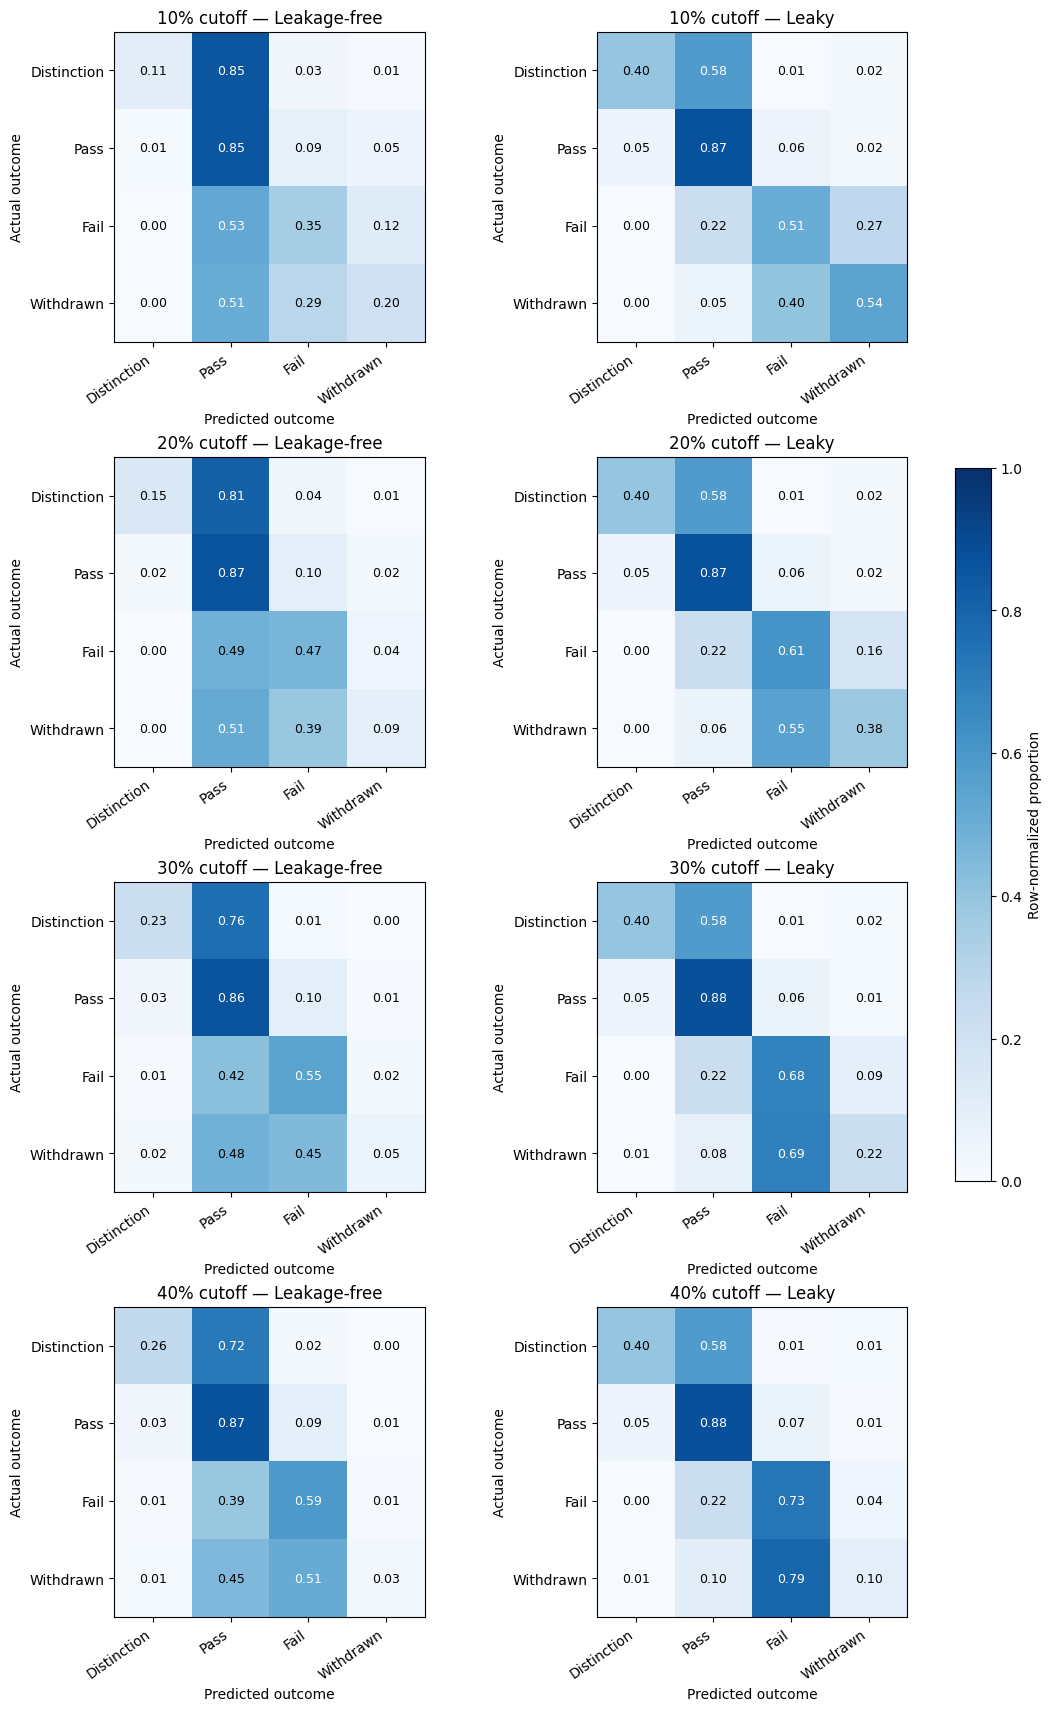

Saved: /content/drive/MyDrive/AI_Research_Paper_1/model_artifacts/Supplementary_Figure_S1_Logistic_Regression.png


In [5]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cutoffs = [10, 20, 30, 40]
conditions = [
    ("Leakage_Free", "Leakage-free"),
    ("Leaky", "Leaky")
]
classes = ["Distinction", "Pass", "Fail", "Withdrawn"]

fig, axes = plt.subplots(
    4, 2, figsize=(11, 17),
    constrained_layout=True
)

for i, cutoff in enumerate(cutoffs):
    for j, (condition_file, condition_label) in enumerate(conditions):
        filename = (
            f"confusion_normalized_Logistic_Regression_"
            f"{condition_file}_{cutoff}.csv"
        )

        matrix = pd.read_csv(
            os.path.join(MODEL_ARTIFACT_PATH, filename),
            index_col=0
        ).loc[classes, classes].to_numpy(dtype=float)

        ax = axes[i, j]
        image = ax.imshow(
            matrix, cmap="Blues", vmin=0, vmax=1
        )

        for r in range(4):
            for c in range(4):
                value = matrix[r, c]
                ax.text(
                    c, r, f"{value:.2f}",
                    ha="center", va="center",
                    fontsize=9,
                    color="white" if value > 0.5 else "black"
                )

        ax.set_xticks(range(4), classes, rotation=35, ha="right")
        ax.set_yticks(range(4), classes)
        ax.set_xlabel("Predicted outcome")
        ax.set_ylabel("Actual outcome")
        ax.set_title(
            f"{cutoff}% cutoff — {condition_label}",
            fontsize=12
        )

fig.colorbar(
    image, ax=axes,
    shrink=0.45,
    label="Row-normalized proportion"
)

output_path = os.path.join(
    MODEL_ARTIFACT_PATH,
    "Supplementary_Figure_S1_Logistic_Regression.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


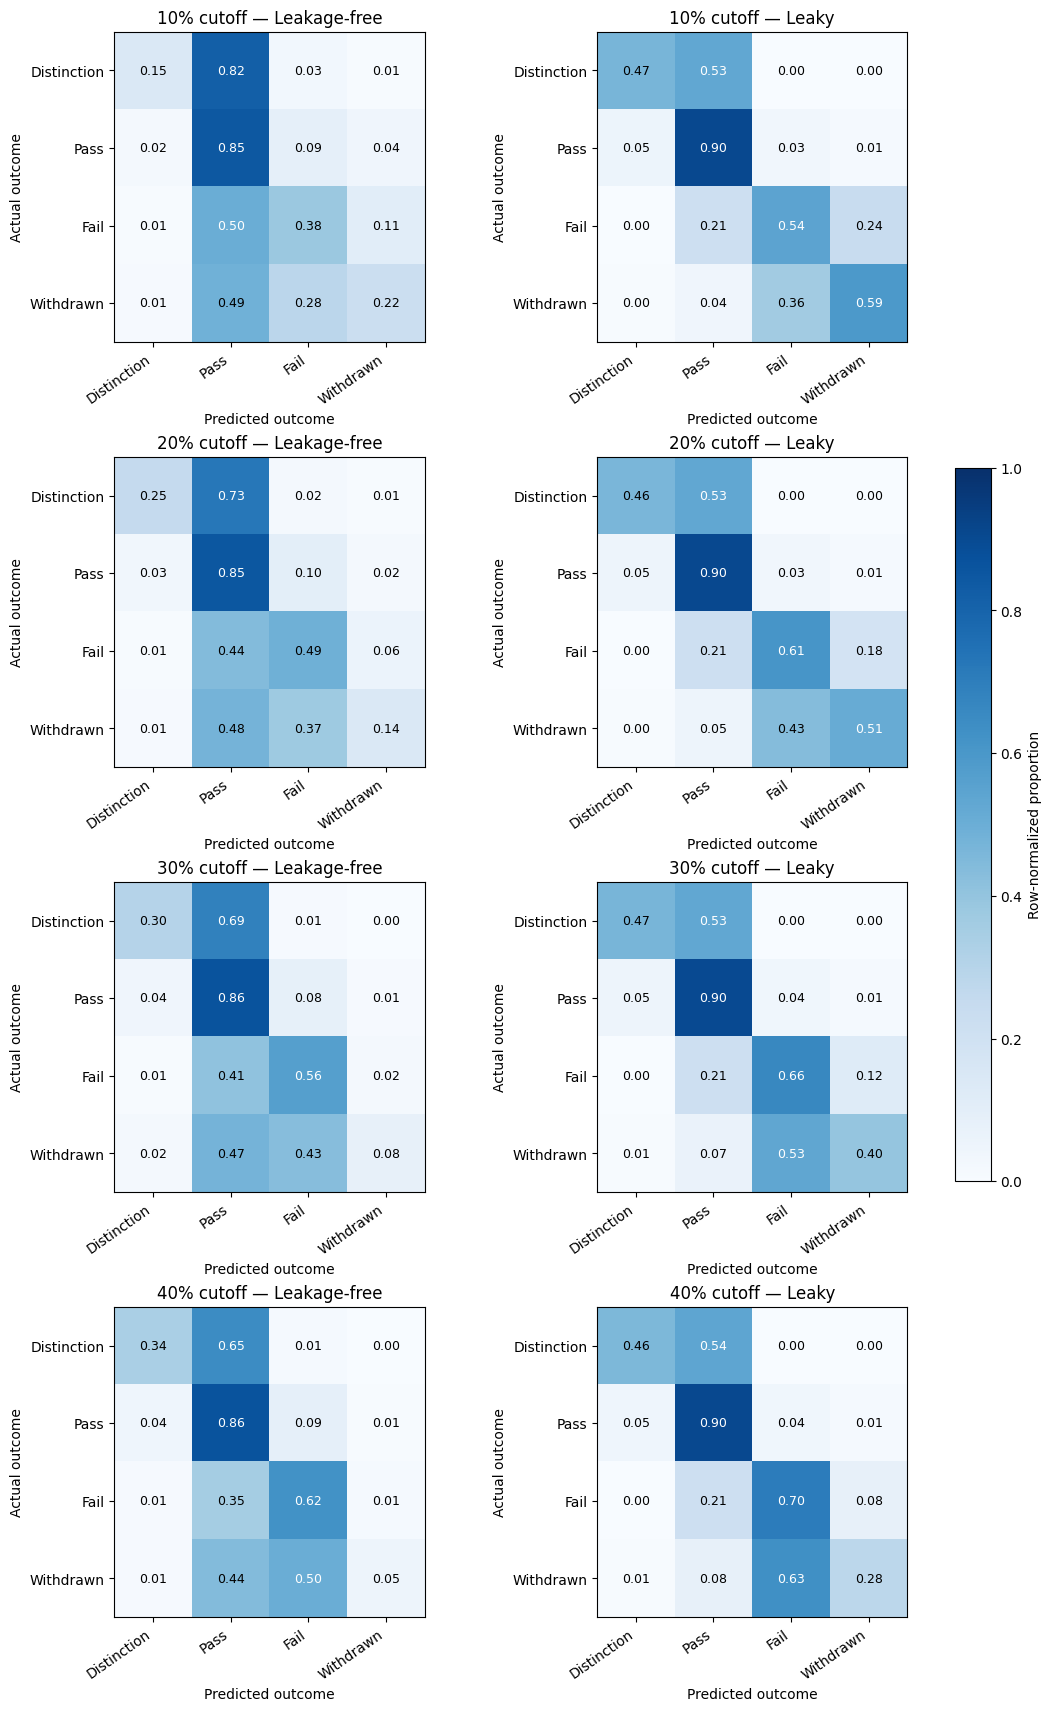

Saved: /content/drive/MyDrive/AI_Research_Paper_1/model_artifacts/Supplementary_Figure_S2_XGBoost.png


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cutoffs = [10, 20, 30, 40]
conditions = [
    ("Leakage_Free", "Leakage-free"),
    ("Leaky", "Leaky")
]
classes = ["Distinction", "Pass", "Fail", "Withdrawn"]

fig, axes = plt.subplots(
    4, 2, figsize=(11, 17),
    constrained_layout=True
)

for i, cutoff in enumerate(cutoffs):
    for j, (condition_file, condition_label) in enumerate(conditions):
        filename = (
            f"confusion_normalized_XGBoost_"
            f"{condition_file}_{cutoff}.csv"
        )

        matrix = pd.read_csv(
            os.path.join(MODEL_ARTIFACT_PATH, filename),
            index_col=0
        ).loc[classes, classes].to_numpy(dtype=float)

        ax = axes[i, j]
        image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)

        for r in range(4):
            for c in range(4):
                value = matrix[r, c]
                ax.text(
                    c, r, f"{value:.2f}",
                    ha="center", va="center",
                    fontsize=9,
                    color="white" if value > 0.5 else "black"
                )

        ax.set_xticks(range(4), classes, rotation=35, ha="right")
        ax.set_yticks(range(4), classes)
        ax.set_xlabel("Predicted outcome")
        ax.set_ylabel("Actual outcome")
        ax.set_title(f"{cutoff}% cutoff — {condition_label}", fontsize=12)

fig.colorbar(
    image, ax=axes,
    shrink=0.45,
    label="Row-normalized proportion"
)

output_path = os.path.join(
    MODEL_ARTIFACT_PATH,
    "Supplementary_Figure_S2_XGBoost.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)

In [6]:
# ============================================================
# REVIEWER REVISION — STEP 9
# Verify probability sums and recompute calibration metrics
# after exact row normalization
# ============================================================

import numpy as np
import pandas as pd
import os
import joblib

from sklearn.metrics import log_loss


def normalize_probability_rows(probabilities):

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    row_sums = probabilities.sum(
        axis=1,
        keepdims=True
    )

    if np.any(row_sums <= 0):
        raise ValueError(
            "Invalid probability row with sum <= 0."
        )

    return probabilities / row_sums


corrected_calibration_rows = []
probability_diagnostics = []


for p in [10, 20, 30, 40]:

    # ----------------------------------------
    # Reload paired test datasets
    # ----------------------------------------

    lf = pd.read_csv(
        os.path.join(
            MODEL_DATA_PATH,
            f"leakage_free_{p}.csv"
        )
    )

    leaky = pd.read_csv(
        os.path.join(
            LEAKY_PATH,
            f"leaky_{p}.csv"
        )
    )

    lf = canonicalize_dataset(
        lf, p, "leakage_free"
    )

    leaky = canonicalize_dataset(
        leaky, p, "leaky"
    )

    lf = lf.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = leaky.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    lf = (
        lf.sort_values(keys)
        .reset_index(drop=True)
    )

    leaky = (
        leaky.sort_values(keys)
        .reset_index(drop=True)
    )

    lf_test = (
        lf.loc[lf["split"] == "test"]
        .reset_index(drop=True)
    )

    leaky_test = (
        leaky.loc[leaky["split"] == "test"]
        .reset_index(drop=True)
    )

    y_true = (
        lf_test["final_result"]
        .map(target_mapping)
        .astype(int)
        .to_numpy()
    )

    models = {

        "XGBoost Leakage-Free":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"xgb_lf_{p}.joblib"
                )
            ),

        "XGBoost Leaky":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"xgb_leaky_{p}.joblib"
                )
            ),

        "Logistic Regression Leakage-Free":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"logistic_lf_{p}.joblib"
                )
            ),

        "Logistic Regression Leaky":
            joblib.load(
                os.path.join(
                    MODEL_ARTIFACT_PATH,
                    f"logistic_leaky_{p}.joblib"
                )
            )
    }

    for model_name, model in models.items():

        condition = (
            "Leaky"
            if model_name.endswith("Leaky")
            else "Leakage-Free"
        )

        algorithm = (
            "XGBoost"
            if model_name.startswith("XGBoost")
            else "Logistic Regression"
        )

        X = (
            leaky_test[primary_features]
            if condition == "Leaky"
            else lf_test[primary_features]
        )

        probs_raw = aligned_probabilities(
            model,
            X
        )

        raw_sums = probs_raw.sum(
            axis=1
        )

        probability_diagnostics.append({

            "Cutoff": f"{p}%",

            "Algorithm": algorithm,

            "Condition": condition,

            "Min_Row_Sum":
                raw_sums.min(),

            "Max_Row_Sum":
                raw_sums.max(),

            "Max_Absolute_Deviation":
                np.max(
                    np.abs(
                        raw_sums - 1.0
                    )
                )
        })

        # Exact normalization
        probs = normalize_probability_rows(
            probs_raw
        )

        # Recompute metrics
        ll = log_loss(
            y_true,
            probs,
            labels=[0, 1, 2, 3]
        )

        brier = multiclass_brier(
            y_true,
            probs
        )

        ece = classwise_ece(
            y_true,
            probs,
            n_bins=10
        )

        corrected_calibration_rows.append({

            "Cutoff":
                f"{p}%",

            "Algorithm":
                algorithm,

            "Condition":
                condition,

            "Log_Loss":
                ll,

            "Multiclass_Brier":
                brier,

            "Macro_Classwise_ECE":
                ece
        })


probability_diagnostics = pd.DataFrame(
    probability_diagnostics
)

corrected_calibration_table = pd.DataFrame(
    corrected_calibration_rows
)


print(
    "\n=== PROBABILITY ROW-SUM DIAGNOSTICS ===\n"
)

print(
    probability_diagnostics
    .round(10)
    .to_string(index=False)
)


print(
    "\n=== CORRECTED CALIBRATION METRICS ===\n"
)

print(
    corrected_calibration_table
    .round(4)
    .to_string(index=False)
)


# Save corrected values
corrected_calibration_table.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_calibration_metrics_corrected.csv"
    ),
    index=False
)

probability_diagnostics.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "probability_sum_diagnostics.csv"
    ),
    index=False
)


print(
    "\n✅ Probability rows checked."
)

print(
    "✅ Probabilities normalized exactly to sum to 1."
)

print(
    "✅ Calibration metrics recomputed without ambiguity."
)


=== PROBABILITY ROW-SUM DIAGNOSTICS ===

Cutoff           Algorithm    Condition  Min_Row_Sum  Max_Row_Sum  Max_Absolute_Deviation
   10%             XGBoost Leakage-Free          1.0          1.0            8.010000e-08
   10%             XGBoost        Leaky          1.0          1.0            8.480000e-08
   10% Logistic Regression Leakage-Free          1.0          1.0            0.000000e+00
   10% Logistic Regression        Leaky          1.0          1.0            0.000000e+00
   20%             XGBoost Leakage-Free          1.0          1.0            8.380000e-08
   20%             XGBoost        Leaky          1.0          1.0            8.360000e-08
   20% Logistic Regression Leakage-Free          1.0          1.0            0.000000e+00
   20% Logistic Regression        Leaky          1.0          1.0            0.000000e+00
   30%             XGBoost Leakage-Free          1.0          1.0            8.380000e-08
   30%             XGBoost        Leaky          1.0      

In [7]:
# ============================================================
# REVIEWER REVISION — STEP 10
# Cohort-description table by cutoff and split
# ============================================================

import os
import pandas as pd

cohort_rows = []

for p in [10, 20, 30, 40]:

    # Load leakage-free dataset because LF and leaky
    # conditions contain the same eligible registrations
    df = pd.read_csv(
        os.path.join(
            MODEL_DATA_PATH,
            f"leakage_free_{p}.csv"
        )
    )

    df = canonicalize_dataset(
        df,
        p,
        "leakage_free"
    )

    df = df.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    for split_name in ["train", "test"]:

        part = df.loc[
            df["split"] == split_name
        ].copy()

        counts = (
            part["final_result"]
            .value_counts()
        )

        cohort_rows.append({

            "Cutoff":
                f"{p}%",

            "Split":
                split_name.capitalize(),

            "Registrations_Total":
                len(part),

            "Unique_Students":
                part["id_student"].nunique(),

            "Distinction":
                int(
                    counts.get(
                        "Distinction", 0
                    )
                ),

            "Pass":
                int(
                    counts.get(
                        "Pass", 0
                    )
                ),

            "Fail":
                int(
                    counts.get(
                        "Fail", 0
                    )
                ),

            "Withdrawn":
                int(
                    counts.get(
                        "Withdrawn", 0
                    )
                )
        })


cohort_table = pd.DataFrame(
    cohort_rows
)

print(
    "\n=== COHORT DESCRIPTION BY CUTOFF AND SPLIT ===\n"
)

print(
    cohort_table.to_string(
        index=False
    )
)

# Verify class counts equal total registrations
check = (
    cohort_table[
        [
            "Distinction",
            "Pass",
            "Fail",
            "Withdrawn"
        ]
    ]
    .sum(axis=1)
)

assert (
    check
    ==
    cohort_table[
        "Registrations_Total"
    ]
).all()

cohort_table.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_cohort_description.csv"
    ),
    index=False
)

print(
    "\n✅ All class counts sum correctly to total registrations."
)

print(
    "✅ Cohort table saved to model_artifacts."
)


=== COHORT DESCRIPTION BY CUTOFF AND SPLIT ===

Cutoff Split  Registrations_Total  Unique_Students  Distinction  Pass  Fail  Withdrawn
   10% Train                22138            19953         2442  9882  5570       4244
   10%  Test                 5514             4991          580  2472  1461       1001
   20% Train                21274            19335         2444  9884  5572       3374
   20%  Test                 5321             4843          580  2472  1461        808
   30% Train                20619            18835         2444  9886  5572       2717
   30%  Test                 5164             4724          580  2472  1462        650
   40% Train                20091            18446         2444  9888  5574       2185
   40%  Test                 5028             4627          580  2472  1462        514

✅ All class counts sum correctly to total registrations.
✅ Cohort table saved to model_artifacts.


In [8]:
# ============================================================
# REVIEWER REVISION — STEP 11
# Exact predictor inventory
# ============================================================

print("=== PRIMARY FEATURES ===")
print("Total:", len(primary_features))

for i, feature in enumerate(primary_features, start=1):
    print(f"{i:02d}. {feature}")

print("\n=== NUMERIC FEATURES ===")
print("Total:", len(numeric_features))

for feature in numeric_features:
    print("-", feature)

print("\n=== CATEGORICAL FEATURES ===")
print("Total:", len(categorical_features))

for feature in categorical_features:
    print("-", feature)

=== PRIMARY FEATURES ===
Total: 25
01. code_module
02. code_presentation
03. highest_education
04. imd_band
05. age_band
06. num_of_prev_attempts
07. studied_credits
08. date_registration
09. precourse_clicks
10. precourse_active_days
11. precourse_unique_sites
12. vle_clicks
13. vle_active_days
14. vle_unique_sites
15. content_clicks
16. forum_clicks
17. navigation_clicks
18. assessments_submitted
19. tma_submitted
20. cma_submitted
21. late_submissions
22. mean_submission_delay
23. scored_assessments
24. mean_score
25. has_score

=== NUMERIC FEATURES ===
Total: 20
- num_of_prev_attempts
- studied_credits
- date_registration
- precourse_clicks
- precourse_active_days
- precourse_unique_sites
- vle_clicks
- vle_active_days
- vle_unique_sites
- content_clicks
- forum_clicks
- navigation_clicks
- assessments_submitted
- tma_submitted
- cma_submitted
- late_submissions
- mean_submission_delay
- scored_assessments
- mean_score
- has_score

=== CATEGORICAL FEATURES ===
Total: 5
- code_modul

In [9]:
# ============================================================
# REVIEWER REVISION — STEP 12
# Complete predictor definition and temporal-availability table
# ============================================================

import os
import pandas as pd

feature_dictionary = pd.DataFrame([
    # --------------------------------------------------------
    # STATIC / BACKGROUND
    # --------------------------------------------------------
    {
        "Predictor": "code_module",
        "Feature_Family": "Static/Background",
        "Data_Type": "Categorical",
        "Definition": "Identifier of the OULAD module.",
        "Temporal_Availability": "Known before prediction; constant for the student-module registration."
    },
    {
        "Predictor": "code_presentation",
        "Feature_Family": "Static/Background",
        "Data_Type": "Categorical",
        "Definition": "Identifier of the module presentation/session.",
        "Temporal_Availability": "Known before prediction; constant for the student-module registration."
    },
    {
        "Predictor": "highest_education",
        "Feature_Family": "Static/Background",
        "Data_Type": "Categorical",
        "Definition": "Student's highest recorded educational qualification.",
        "Temporal_Availability": "Baseline student-information variable available before the prediction cutoff."
    },
    {
        "Predictor": "imd_band",
        "Feature_Family": "Static/Background",
        "Data_Type": "Categorical",
        "Definition": "Index of Multiple Deprivation band recorded for the student; missing values represented as 'Unknown'.",
        "Temporal_Availability": "Baseline student-information variable available before the prediction cutoff."
    },
    {
        "Predictor": "age_band",
        "Feature_Family": "Static/Background",
        "Data_Type": "Categorical",
        "Definition": "Student age-band category.",
        "Temporal_Availability": "Baseline student-information variable available before the prediction cutoff."
    },
    {
        "Predictor": "num_of_prev_attempts",
        "Feature_Family": "Static/Background",
        "Data_Type": "Numeric",
        "Definition": "Number of previous attempts recorded for the module.",
        "Temporal_Availability": "Historical variable available before the prediction cutoff."
    },
    {
        "Predictor": "studied_credits",
        "Feature_Family": "Static/Background",
        "Data_Type": "Numeric",
        "Definition": "Number of credits studied by the student in the presentation.",
        "Temporal_Availability": "Registration-related variable available before the prediction cutoff."
    },
    {
        "Predictor": "date_registration",
        "Feature_Family": "Static/Background",
        "Data_Type": "Numeric",
        "Definition": "Student registration day relative to the start of the module presentation.",
        "Temporal_Availability": "Observed at registration; only students registered on or before the cutoff were eligible."
    },

    # --------------------------------------------------------
    # PRE-COURSE VLE
    # --------------------------------------------------------
    {
        "Predictor": "precourse_clicks",
        "Feature_Family": "Pre-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Total VLE clicks recorded before course Day 0.",
        "Temporal_Availability": "Calculated only from VLE events occurring from the student's registration date up to, but not including, Day 0."
    },
    {
        "Predictor": "precourse_active_days",
        "Feature_Family": "Pre-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Number of distinct pre-course days on which the student recorded VLE activity.",
        "Temporal_Availability": "Calculated from activity between registration and Day 0 only."
    },
    {
        "Predictor": "precourse_unique_sites",
        "Feature_Family": "Pre-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Number of distinct VLE sites accessed before course Day 0.",
        "Temporal_Availability": "Calculated from activity between registration and Day 0 only."
    },

    # --------------------------------------------------------
    # IN-COURSE VLE
    # --------------------------------------------------------
    {
        "Predictor": "vle_clicks",
        "Feature_Family": "In-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Total in-course VLE clicks accumulated by the prediction cutoff.",
        "Temporal_Availability": "Leakage-free condition used events from Day 0 through the cutoff and no earlier than the student's registration date; leaky condition used full-course values."
    },
    {
        "Predictor": "vle_active_days",
        "Feature_Family": "In-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Number of distinct in-course days with recorded VLE activity.",
        "Temporal_Availability": "Leakage-free condition used activity through the cutoff only; leaky condition used full-course activity."
    },
    {
        "Predictor": "vle_unique_sites",
        "Feature_Family": "In-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Number of distinct VLE sites accessed during the course.",
        "Temporal_Availability": "Leakage-free condition used accesses through the cutoff only; leaky condition used full-course activity."
    },
    {
        "Predictor": "content_clicks",
        "Feature_Family": "In-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Total clicks on VLE activities mapped to the content group.",
        "Temporal_Availability": "Leakage-free condition used content activity through the cutoff only; leaky condition used full-course activity."
    },
    {
        "Predictor": "forum_clicks",
        "Feature_Family": "In-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Total clicks on VLE activities mapped to the forum group.",
        "Temporal_Availability": "Leakage-free condition used forum activity through the cutoff only; leaky condition used full-course activity."
    },
    {
        "Predictor": "navigation_clicks",
        "Feature_Family": "In-course VLE",
        "Data_Type": "Numeric",
        "Definition": "Total clicks on VLE activities mapped to the navigation group.",
        "Temporal_Availability": "Leakage-free condition used navigation activity through the cutoff only; leaky condition used full-course activity."
    },

    # --------------------------------------------------------
    # ASSESSMENT
    # --------------------------------------------------------
    {
        "Predictor": "assessments_submitted",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Number of distinct eligible TMA/CMA assessments submitted.",
        "Temporal_Availability": "Leakage-free condition included non-banked TMA/CMA submissions made on or after registration and no later than the cutoff; leaky condition used full-course submissions."
    },
    {
        "Predictor": "tma_submitted",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Number of tutor-marked assignments (TMAs) submitted.",
        "Temporal_Availability": "Leakage-free condition counted eligible TMA submissions through the cutoff only; leaky condition used full-course submissions."
    },
    {
        "Predictor": "cma_submitted",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Number of computer-marked assignments (CMAs) submitted.",
        "Temporal_Availability": "Leakage-free condition counted eligible CMA submissions through the cutoff only; leaky condition used full-course submissions."
    },
    {
        "Predictor": "late_submissions",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Number of observed submissions made after the scheduled assessment date.",
        "Temporal_Availability": "Calculated only from eligible submissions observed by the cutoff in the leakage-free condition."
    },
    {
        "Predictor": "mean_submission_delay",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Mean difference in days between actual submission date and scheduled assessment date.",
        "Temporal_Availability": "Calculated only from eligible submissions observed by the cutoff in the leakage-free condition."
    },
    {
        "Predictor": "scored_assessments",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Number of submitted assessments with a non-missing score considered available.",
        "Temporal_Availability": "Leakage-free condition required submission by the cutoff and scheduled assessment date on or before the cutoff; leaky condition used full-course score information."
    },
    {
        "Predictor": "mean_score",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Mean score across assessments considered available under the temporal rule.",
        "Temporal_Availability": "Leakage-free condition used scores only when the assessment had been submitted by the cutoff and its scheduled assessment date was on or before the cutoff."
    },
    {
        "Predictor": "has_score",
        "Feature_Family": "Assessment",
        "Data_Type": "Numeric",
        "Definition": "Indicator equal to 1 when at least one temporally eligible assessment score was available, otherwise 0.",
        "Temporal_Availability": "Derived from scored_assessments using the same conservative cutoff-based score-availability rule."
    }
])

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(feature_dictionary) == 25

assert set(feature_dictionary["Predictor"]) == set(primary_features)

assert (
    feature_dictionary["Predictor"].nunique()
    == 25
)

print(
    "\n=== COMPLETE 25-PREDICTOR FEATURE DICTIONARY ===\n"
)

print(
    feature_dictionary.to_string(
        index=False
    )
)

print(
    "\n=== FEATURE FAMILY COUNTS ===\n"
)

print(
    feature_dictionary[
        "Feature_Family"
    ].value_counts()
)

# Save
feature_dictionary.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_feature_dictionary.csv"
    ),
    index=False
)

print(
    "\n✅ All 25 model predictors accounted for."
)

print(
    "✅ Feature definitions and temporal rules documented."
)

print(
    "✅ Feature dictionary saved to model_artifacts."
)


=== COMPLETE 25-PREDICTOR FEATURE DICTIONARY ===

             Predictor    Feature_Family   Data_Type                                                                                              Definition                                                                                                                                                    Temporal_Availability
           code_module Static/Background Categorical                                                                         Identifier of the OULAD module.                                                                                                   Known before prediction; constant for the student-module registration.
     code_presentation Static/Background Categorical                                                          Identifier of the module presentation/session.                                                                                                   Known before prediction; constant for the 

In [10]:
# ============================================================
# REVIEWER REVISION — STEP 13
# Fixed-cohort robustness analysis
# Same test registrations evaluated at all four cutoffs
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

KEYS = [
    "code_module",
    "code_presentation",
    "id_student"
]

CUTOFFS = [10, 20, 30, 40]


# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def fw_confusion_rate(y_true, y_pred):

    fail_label = target_mapping["Fail"]
    withdraw_label = target_mapping["Withdrawn"]

    eligible = (
        (y_true == fail_label)
        |
        (y_true == withdraw_label)
    )

    denominator = eligible.sum()

    if denominator == 0:
        return np.nan

    f_to_w = (
        (y_true == fail_label)
        &
        (y_pred == withdraw_label)
    ).sum()

    w_to_f = (
        (y_true == withdraw_label)
        &
        (y_pred == fail_label)
    ).sum()

    return (
        f_to_w + w_to_f
    ) / denominator


# ------------------------------------------------------------
# 1. Load paired test sets for every cutoff
# ------------------------------------------------------------

cutoff_test_sets = {}

for p in CUTOFFS:

    lf = pd.read_csv(
        os.path.join(
            MODEL_DATA_PATH,
            f"leakage_free_{p}.csv"
        )
    )

    leaky = pd.read_csv(
        os.path.join(
            LEAKY_PATH,
            f"leaky_{p}.csv"
        )
    )

    lf = canonicalize_dataset(
        lf,
        p,
        "leakage_free"
    )

    leaky = canonicalize_dataset(
        leaky,
        p,
        "leaky"
    )

    lf = lf.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = leaky.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    lf = (
        lf.loc[
            lf["split"] == "test"
        ]
        .sort_values(KEYS)
        .reset_index(drop=True)
    )

    leaky = (
        leaky.loc[
            leaky["split"] == "test"
        ]
        .sort_values(KEYS)
        .reset_index(drop=True)
    )

    assert lf[KEYS].equals(
        leaky[KEYS]
    )

    cutoff_test_sets[p] = {
        "lf": lf,
        "leaky": leaky
    }


# ------------------------------------------------------------
# 2. Find registrations present at ALL FOUR cutoffs
# ------------------------------------------------------------

common_keys = None

for p in CUTOFFS:

    keys_p = (
        cutoff_test_sets[p]["lf"][
            KEYS
        ]
        .drop_duplicates()
    )

    if common_keys is None:

        common_keys = keys_p.copy()

    else:

        common_keys = common_keys.merge(
            keys_p,
            on=KEYS,
            how="inner"
        )


common_keys = (
    common_keys
    .drop_duplicates()
    .sort_values(KEYS)
    .reset_index(drop=True)
)

print(
    "\n=== FIXED-COHORT DEFINITION ===\n"
)

print(
    "Common test registrations:",
    len(common_keys)
)

print(
    "Unique students:",
    common_keys[
        "id_student"
    ].nunique()
)


# ------------------------------------------------------------
# 3. Evaluate all models on exactly this same cohort
# ------------------------------------------------------------

fixed_rows = []

for p in CUTOFFS:

    lf = cutoff_test_sets[p]["lf"].merge(
        common_keys,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    leaky = cutoff_test_sets[p]["leaky"].merge(
        common_keys,
        on=KEYS,
        how="inner",
        validate="one_to_one"
    )

    lf = (
        lf.sort_values(KEYS)
        .reset_index(drop=True)
    )

    leaky = (
        leaky.sort_values(KEYS)
        .reset_index(drop=True)
    )

    assert len(lf) == len(common_keys)
    assert len(leaky) == len(common_keys)

    assert lf[KEYS].equals(
        leaky[KEYS]
    )

    assert lf[
        "final_result"
    ].equals(
        leaky[
            "final_result"
        ]
    )

    y_true = (
        lf["final_result"]
        .map(target_mapping)
        .astype(int)
        .to_numpy()
    )

    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    xgb_lf = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"xgb_lf_{p}.joblib"
        )
    )

    xgb_leaky = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"xgb_leaky_{p}.joblib"
        )
    )

    xgb_pred_lf = xgb_lf.predict(
        lf[primary_features]
    )

    xgb_pred_leaky = xgb_leaky.predict(
        leaky[primary_features]
    )

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    lr_lf = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"logistic_lf_{p}.joblib"
        )
    )

    lr_leaky = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"logistic_leaky_{p}.joblib"
        )
    )

    lr_pred_lf_text = lr_lf.predict(
        lf[primary_features]
    )

    lr_pred_leaky_text = lr_leaky.predict(
        leaky[primary_features]
    )

    lr_pred_lf = np.array([
        target_mapping[x]
        for x in lr_pred_lf_text
    ])

    lr_pred_leaky = np.array([
        target_mapping[x]
        for x in lr_pred_leaky_text
    ])

    # --------------------------------------------------------
    # Store metrics
    # --------------------------------------------------------

    model_predictions = [

        (
            "XGBoost",
            "Leakage-Free",
            np.asarray(xgb_pred_lf)
        ),

        (
            "XGBoost",
            "Leaky",
            np.asarray(xgb_pred_leaky)
        ),

        (
            "Logistic Regression",
            "Leakage-Free",
            lr_pred_lf
        ),

        (
            "Logistic Regression",
            "Leaky",
            lr_pred_leaky
        )
    ]

    for algorithm, condition, pred in model_predictions:

        fixed_rows.append({

            "Cutoff":
                f"{p}%",

            "Algorithm":
                algorithm,

            "Condition":
                condition,

            "Accuracy":
                accuracy_score(
                    y_true,
                    pred
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_true,
                    pred
                ),

            "Macro_F1":
                f1_score(
                    y_true,
                    pred,
                    average="macro"
                ),

            "Fail_Withdraw_Confusion":
                fw_confusion_rate(
                    y_true,
                    pred
                )
        })


fixed_cohort_results = pd.DataFrame(
    fixed_rows
)


# ------------------------------------------------------------
# 4. Create paired leakage differences
# ------------------------------------------------------------

difference_rows = []

for p in CUTOFFS:

    for algorithm in [
        "XGBoost",
        "Logistic Regression"
    ]:

        temp = fixed_cohort_results[
            (
                fixed_cohort_results[
                    "Cutoff"
                ] == f"{p}%"
            )
            &
            (
                fixed_cohort_results[
                    "Algorithm"
                ] == algorithm
            )
        ]

        lf_row = temp[
            temp[
                "Condition"
            ] == "Leakage-Free"
        ].iloc[0]

        lk_row = temp[
            temp[
                "Condition"
            ] == "Leaky"
        ].iloc[0]

        difference_rows.append({

            "Cutoff":
                f"{p}%",

            "Algorithm":
                algorithm,

            "Accuracy_Diff_pp":
                (
                    lk_row["Accuracy"]
                    -
                    lf_row["Accuracy"]
                ) * 100,

            "Balanced_Accuracy_Diff_pp":
                (
                    lk_row["Balanced_Accuracy"]
                    -
                    lf_row["Balanced_Accuracy"]
                ) * 100,

            "Macro_F1_Diff_pp":
                (
                    lk_row["Macro_F1"]
                    -
                    lf_row["Macro_F1"]
                ) * 100,

            "FW_Confusion_Diff_pp":
                (
                    lk_row[
                        "Fail_Withdraw_Confusion"
                    ]
                    -
                    lf_row[
                        "Fail_Withdraw_Confusion"
                    ]
                ) * 100
        })


fixed_cohort_differences = pd.DataFrame(
    difference_rows
)


# ------------------------------------------------------------
# 5. Print compact results
# ------------------------------------------------------------

print(
    "\n=== FIXED-COHORT LEAKAGE DIFFERENCES ===\n"
)

print(
    fixed_cohort_differences
    .round(2)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

fixed_cohort_results.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_fixed_cohort_full_results.csv"
    ),
    index=False
)

fixed_cohort_differences.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_fixed_cohort_differences.csv"
    ),
    index=False
)

common_keys.to_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "reviewer_fixed_cohort_registration_keys.csv"
    ),
    index=False
)


print(
    "\n✅ Same registrations evaluated at all four cutoffs."
)

print(
    "✅ Both XGBoost and Logistic Regression evaluated."
)

print(
    "✅ Accuracy, balanced accuracy, macro-F1 and "
    "Fail–Withdraw confusion compared."
)

print(
    "✅ Fixed-cohort results saved."
)


=== FIXED-COHORT DEFINITION ===

Common test registrations: 5026
Unique students: 4626

=== FIXED-COHORT LEAKAGE DIFFERENCES ===

Cutoff           Algorithm  Accuracy_Diff_pp  Balanced_Accuracy_Diff_pp  Macro_F1_Diff_pp  FW_Confusion_Diff_pp
   10%             XGBoost             14.66                      21.98             21.89                 13.58
   10% Logistic Regression             11.26                      17.24             17.90                 17.43
   20%             XGBoost             12.06                      18.28             18.11                 11.20
   20% Logistic Regression              9.69                      15.48             16.76                 15.35
   30%             XGBoost             10.01                      15.73             16.79                  9.98
   30% Logistic Regression              7.86                      11.38             12.53                 12.61
   40%             XGBoost              7.96                      11.65             1